In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as tlk
import seaborn as sns

In [2]:
# Displaying the dataset

df_raw = pd.read_excel("HR Analytics Data.xlsx")
df_raw.head(5)

,Age\tAttrition\tBusinessTravel\tDailyRate\tDepartment\tDistanceFromHome\tEducation\tEducationField\tEmployeeCount\tEmployeeNumber\tEnvironmentSatisfaction\tGender\tHourlyRate\tJobInvolvement\tJobLevel\tJobRole\tJobSatisfaction\tMaritalStatus\tMonthlyIncome\tMonthlyRate\tNumCompaniesWorked\tOver18\tOverTime\tPercentSalaryHike\tPerformanceRating\tRelationshipSatisfaction\tStandardHours\tStockOptionLevel\tTotalWorkingYears\tTrainingTimesLastYear\tWorkLifeBalance\tYearsAtCompany\tYearsInCurrentRole\tYearsSinceLastPromotion\tYearsWithCurrManager
0,41\tYes\tTravel_Rarely\t1102\tSales\t1\t2\tLif...
1,49\tNo\tTravel_Frequently\t279\tResearch & Dev...
2,37\tYes\tTravel_Rarely\t1373\tResearch & Devel...
3,33\tNo\tTravel_Frequently\t1392\tResearch & De...
4,27\tNo\tTravel_Rarely\t591\tResearch & Develop...


- data appears to be in a tab seperated format

In [3]:
# Seperating the single column names into seperate individual columns

column= df_raw.columns[0].split("\t")

In [4]:
# Splitting the rows into individual columns

df= df_raw.iloc[:,0].str.split("\t",expand = True)
df.columns= column

In [5]:
# Visulizing the dataset

df.head(5)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [6]:
# Understanding the data structure and formats

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   object
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   object
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   object
 6   Education                 1470 non-null   object
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   object
 9   EmployeeNumber            1470 non-null   object
 10  EnvironmentSatisfaction   1470 non-null   object
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   object
 13  JobInvolvement            1470 non-null   object
 14  JobLevel                

- some the columns data types are incorrect
- there are no missing values
- there are 1470 entries/captured employees
- the dataset has 35 columns

In [7]:
# making a copy the original dataset

dfc= df.copy()

In [8]:
# making another copy of the data
dfs=df.copy()

# Data cleaning

In [9]:
# Converting columns to appropriate data types
dfc= dfc.apply(pd.to_numeric, errors='ignore')
dfc.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

C:\Users\User\AppData\Local\Temp\ipykernel_14940\321298269.py:2: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  dfc= dfc.apply(pd.to_numeric, errors='ignore')


In [10]:
# Checking for duplicates

dfs.duplicated().sum()

np.int64(0)

In [11]:
# dropping unwanted columns

dfc=dfc.drop(columns= 'Over18', axis =1)

- After correcting the datatypes, there were still no missing values.
- 'over 18' column was dropped
- And no duplicate values

In [12]:
# List of columns you want to convert
cols_to_convert = [
    'Age', 'DailyRate', 'DistanceFromHome', 'MonthlyIncome', 'MonthlyRate', 
    'NumCompaniesWorked', 'PercentSalaryHike', 'StandardHours', 
    'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager','HourlyRate'
]

# Loop through each column (ensure the next line is indented!)
for col in cols_to_convert:
    dfs[col] = pd.to_numeric(df[col], errors='coerce')
dfs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   object
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   object
 9   EmployeeNumber            1470 non-null   object
 10  EnvironmentSatisfaction   1470 non-null   object
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   object
 14  JobLevel                

Binning the numerical columns fo future use:

In [13]:
# binning dialy rate
b= [100,400,800,1200,1600]
l= ['Low','Standard','High','Executive']      
dfs['Dailyrates_group'] = pd.cut(dfs['DailyRate'],bins=b,labels=l,include_lowest=True)     

In [14]:
# binning Age
bi= [18,29,40,51,62]
la= ['Younge Adult','Adult','Middle Aged','Seniors']
dfs['Age_group']= pd.cut(dfs['Age'],bins=bi,labels=la,include_lowest=True)           

In [15]:
# binning distance from home
bins= [1,8,15,22,29]
labels= ['very close','close','far','very far']
dfs['dist_from_home_group']= pd.cut(dfs['DistanceFromHome'],bins=bins,labels=labels,include_lowest=True)        

In [16]:
# binning monthly income
bins= [1000,5000,10000,15000,20000]
labels= ['low','medium','high','executive']
dfs['MonthlyIncome_group']= pd.cut(dfs['MonthlyIncome'],bins=bins,labels=labels,include_lowest=True)        

In [17]:
# binning Num Companies Worked
bins= [0,2,5,8,11]
labels= ['entry level','junior','senior','executive']
dfs['NumCompaniesWorked_worked_group']= pd.cut(dfs['NumCompaniesWorked'],bins=bins,labels=labels,include_lowest=True)       

In [18]:
# binning Years Since Last Promotion
bins= [0,3,7,11,15]
labels= ['Recent','Eligible','Stagnant','Deeply Stagnant']
dfs['YearsSinceLastPromotion_group']= pd.cut(dfs['YearsSinceLastPromotion'],bins=bins,labels=labels,include_lowest=True)       

In [19]:
# binning Training Times Last Year
bins= [0,2,5,8]
labels= ['Rarely','Frequently','Consistently']
dfs['TrainingTimesLastYear_group']= pd.cut(dfs['TrainingTimesLastYear'],bins=bins,labels=labels,include_lowest=True)      

In [20]:
# Droping unwanted columns

dfs= dfs.drop(columns=['EmployeeNumber','EmployeeCount','Over18','StandardHours'],axis=1)

## Data Exploration

In [21]:
# finding the distribution of employee attrition
attrition=df['Attrition'].value_counts()
print(attrition)

Attrition
No     1233
Yes     237
Name: count, dtype: int64


- 237 total employees have left the company

Attrition
No     83.88
Yes    16.12
Name: count, dtype: float64


Text(0, 0.5, 'percentage Emloyee')

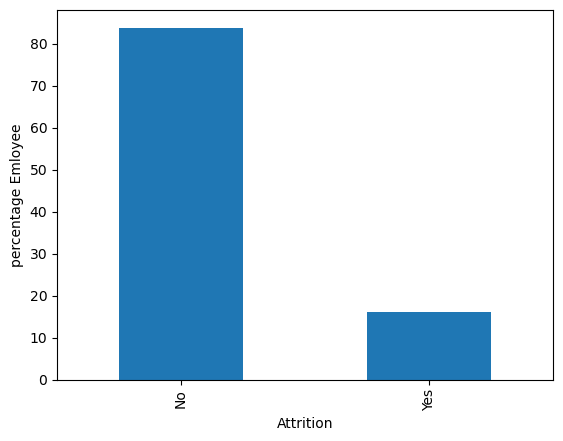

In [22]:
# Rate of attrition

attrition_rate=(df['Attrition'].value_counts()/len(df['Attrition']))*100
print(round(attrition_rate,2))
attrition_rate.plot(kind='bar')
plt.ylabel('percentage Emloyee')

insight:
- Attrition rate is 16.12%
- At a ratio of 5:1, the data is highly imbalanced; more analysis will be done on the data
- for every 5 employee, one has exited

In [23]:
# Understanding the statistcal distribution of the dataset 

dfc.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.00,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.00,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.00,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.00,3.0,4.00,5.0
EmployeeCount,1470.0,1.000000,0.000000,1.0,1.00,1.0,1.00,1.0
EmployeeNumber,1470.0,1024.865306,602.024335,1.0,491.25,1020.5,1555.75,2068.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.00,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.00,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.00,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.00,2.0,3.00,5.0


Initial Insights
- Average age of employees is 37, with 75% of employees below 44 years, and the minimum age is 18 years
- Max years of year since last promotion is 15 years
- Longest tenure at the company is 40 years, while the longest an employee has been in a particular role is 18 years
- Average daily rate is ~802.49$, hourly rate at ~65.89$ and standard work hours at 80 hrs
- Average monthly income is ~6,502.93$, and only 25% of the workforce earns above 8379%, while more than 50% earns below average
- 75% of employees are mid-low level, and 25% put in below-average effort in their jobs and are dissatisfied.
- Also, 75% of the workforce are university graduates and above
- Work relationship/work-life balance/environment is almost average in satisfaction
- Average years spent under a current manager is 4 years, with a maximum of 17 years, while 25% of the workforce has spent more than 7years under their current managers.
- In a total of 6 trainings hosted, only 25% of the workforce managed to attend more than 3 of these trainings.
- Half of the workforce covers 7km(30 minutes drive) to get to the office, while 25% cover more than 14km(1hr drive) to get to work
- Overall performance ratings of employees are slightly above average
- Only 25% of the workforce enjoys Standard/Entry Option Tier equity/stock option, while half are zero

Univariate Analysis

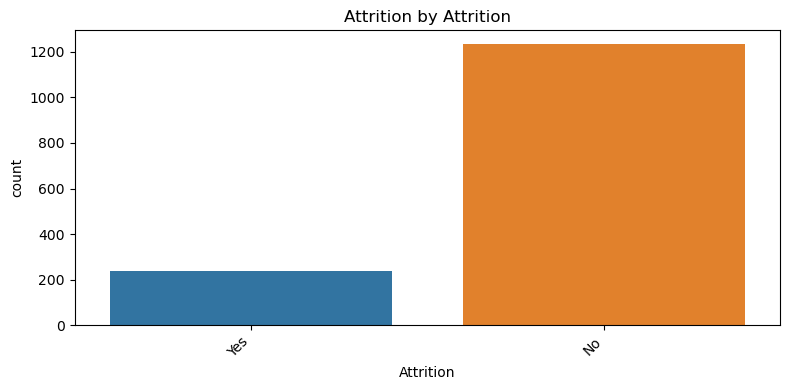

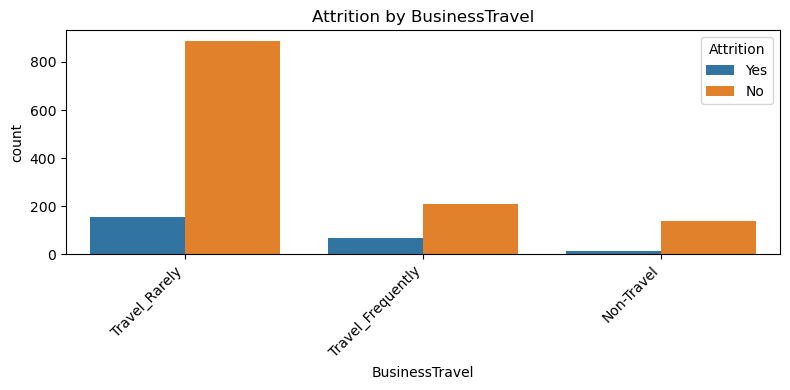

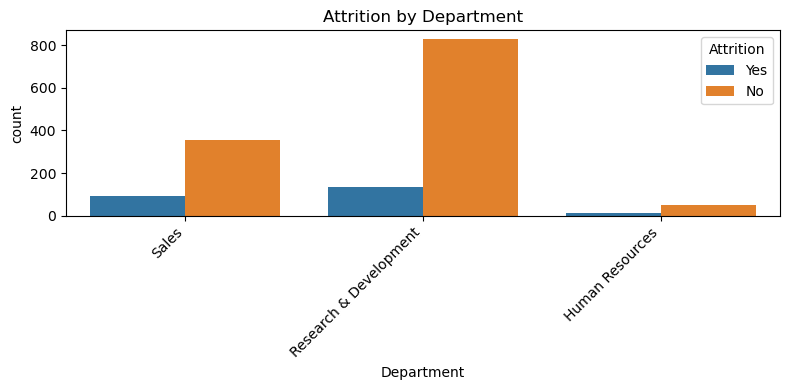

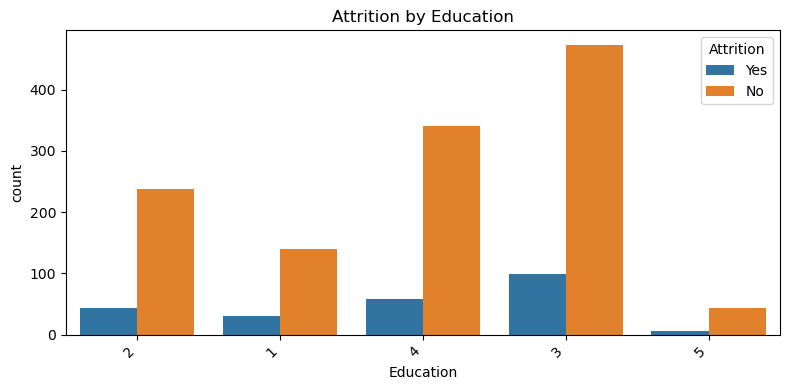

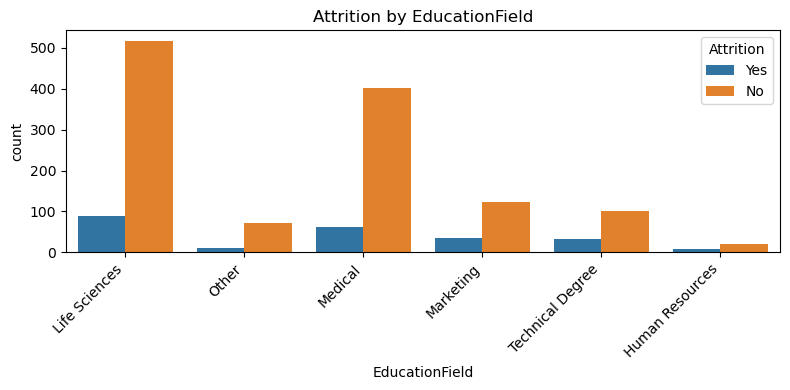

...

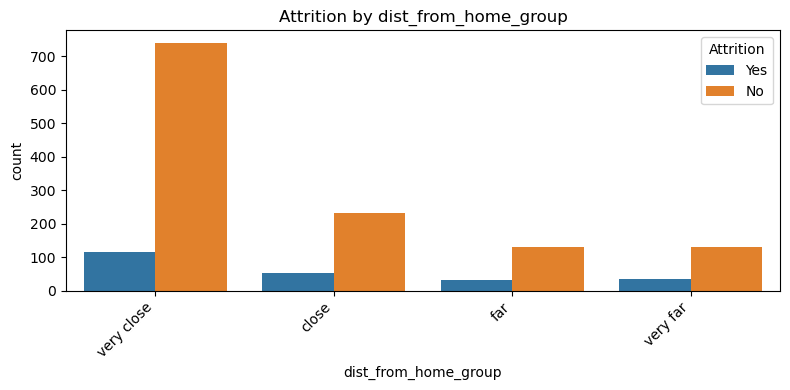

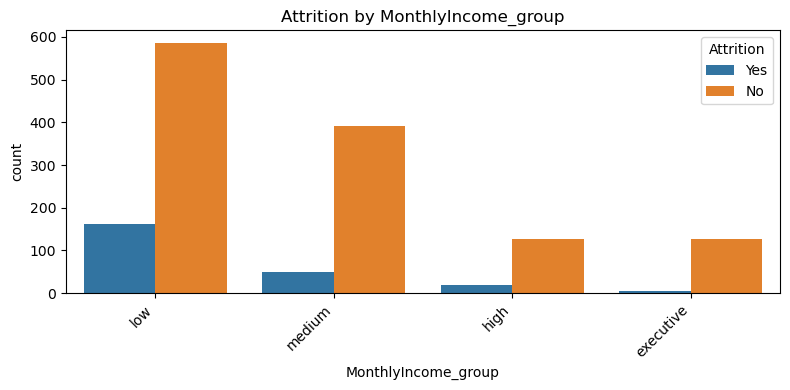

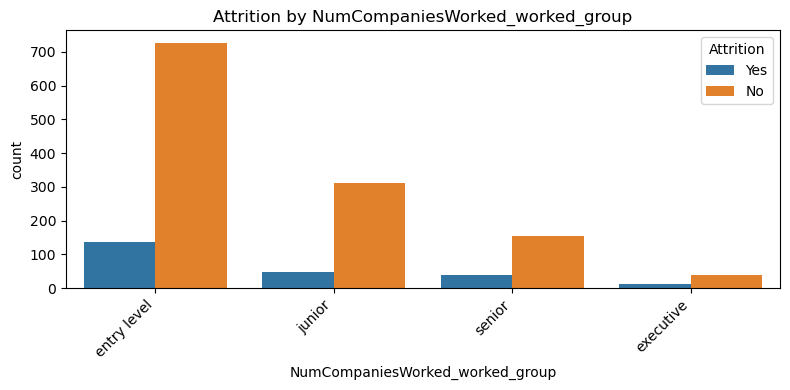

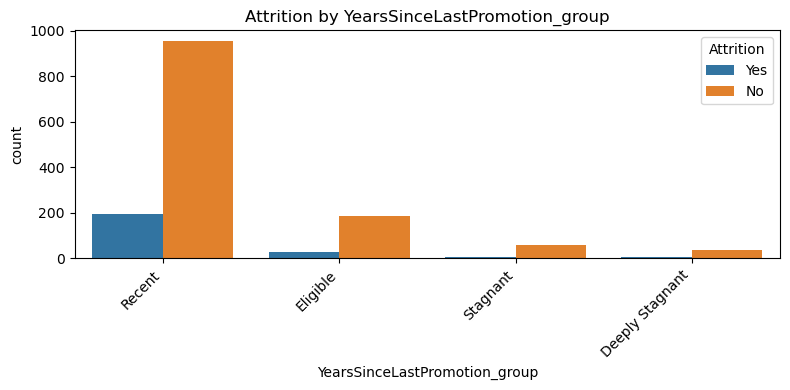

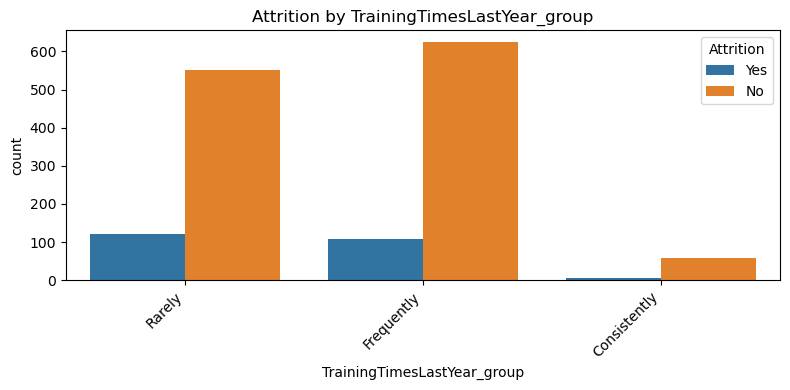

In [24]:
# Distribution of the categorical features
numeric_cols = [
    'Age', 'DailyRate', 'DistanceFromHome', 'MonthlyIncome', 'MonthlyRate', 
    'NumCompaniesWorked', 'PercentSalaryHike', 'StandardHours', 
    'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager','HourlyRate'
]


categorical_cols = dfs.drop(columns=numeric_cols, errors='ignore')


for predictor in categorical_cols.columns:
    fig, ax = plt.subplots(figsize=(8, 4))
    sns.countplot(data=dfs, x=predictor, hue='Attrition', ax=ax)
    plt.title(f'Attrition by {predictor}')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()
    plt.close(fig)

Those more likely to leave
- people who travel frequently are more likely to churn
- people in sales and human resources are more likely to leave
- people with education levels 1 and 3 are more likely to leave
- those in technical, human resources, and other education fields are more likely to leave
- those least satisfied with the environment and least job involvement and job level, and least job satisfaction and least relationship satisfaction
- gender plays no role
- these job roles: Sales reps, human resources, laboratory tech, sales executives, research scientist
- single people
- those who do overtime
- those with high performance rating
- those with no stock options and those with stock option level 3
- those with the worst work-life balance

In [25]:
# Defining your uniplot

def uniplot(dfs, col, title):
    sns.set_style('whitegrid')
    fig, ax = plt.subplots(figsize=(10, 6))
    
    sns.countplot(
        data=dfs, 
        x=col, 
        order=dfs[col].value_counts().index, 
        palette='bright', 
        ax=ax
    )
    
    plt.xticks(rotation=45, ha='right')
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


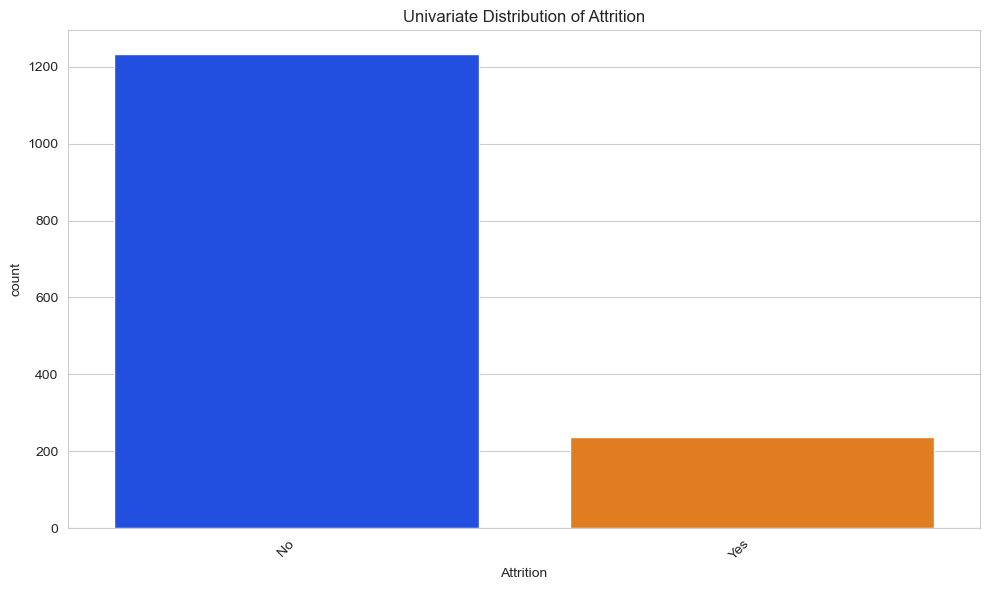

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


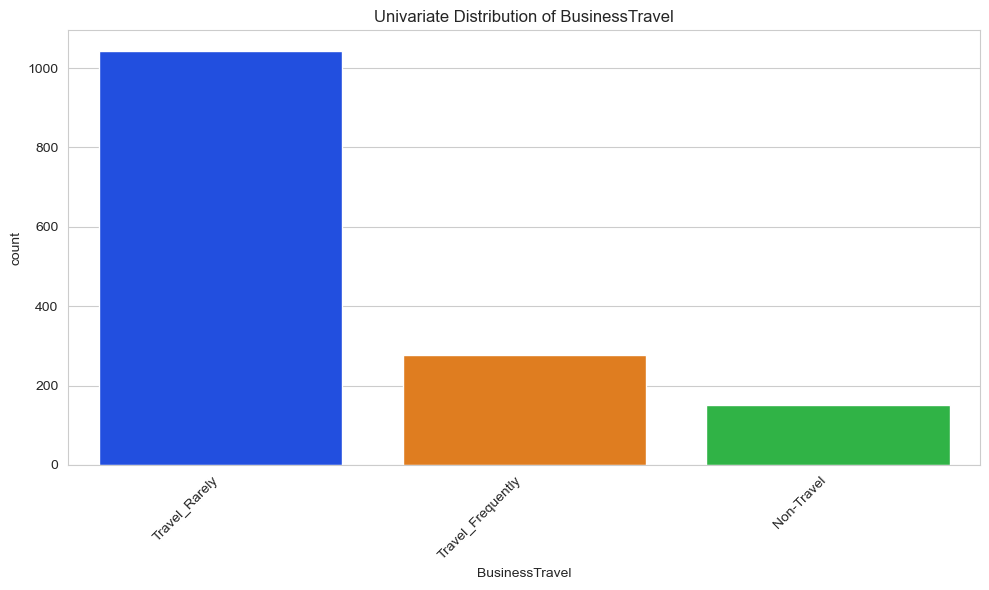

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


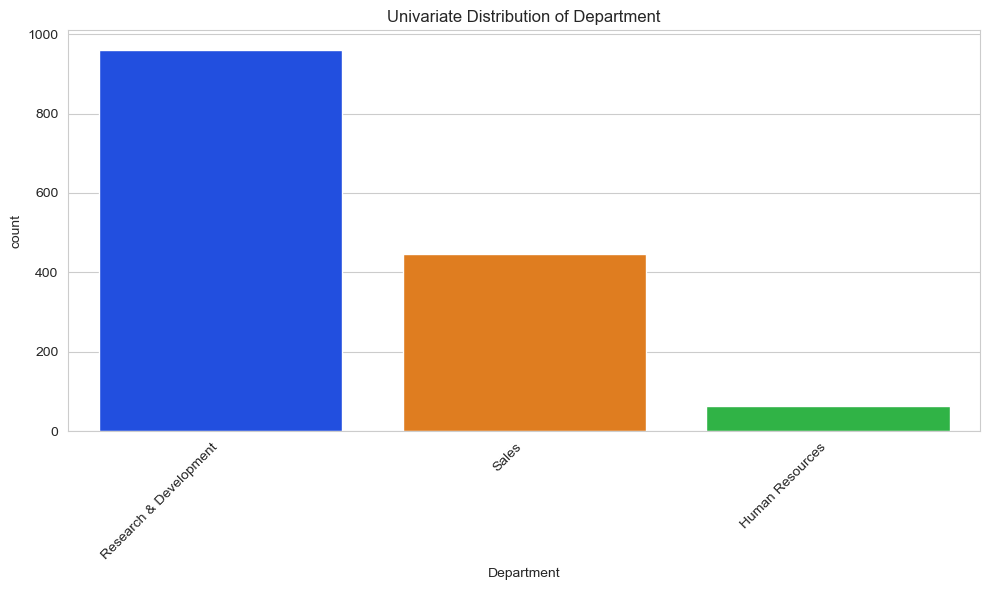

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


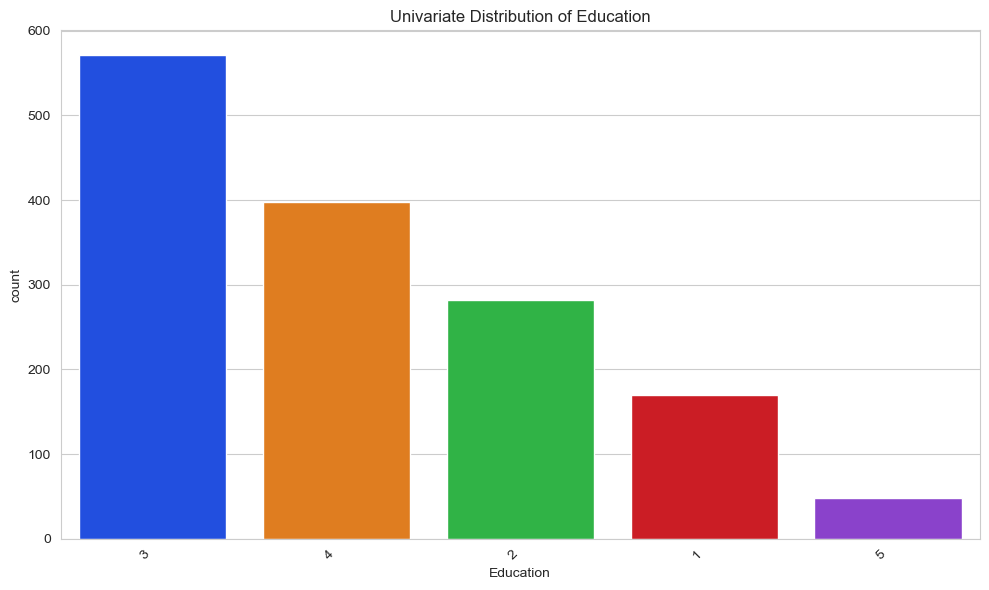

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


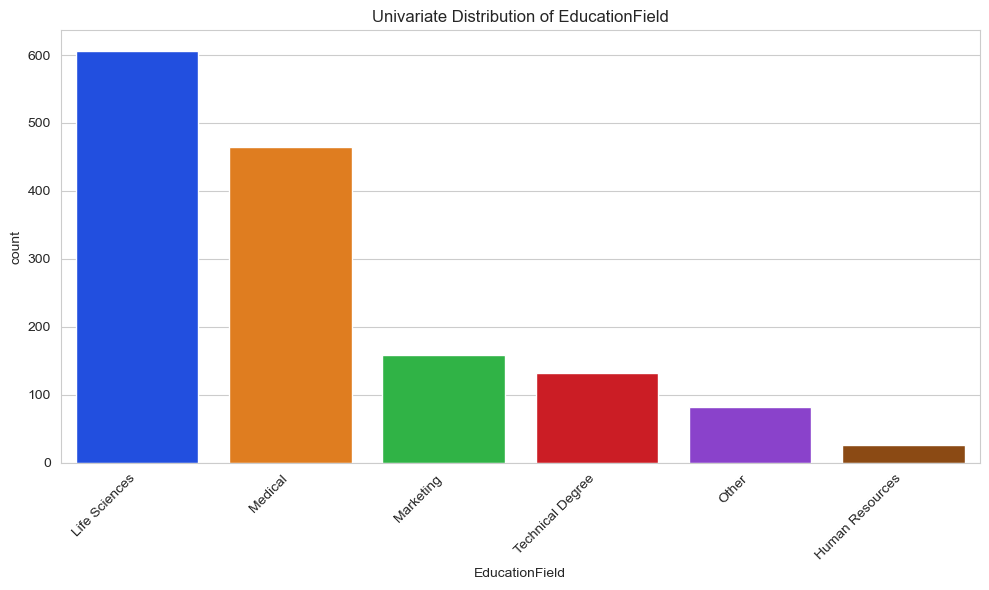

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


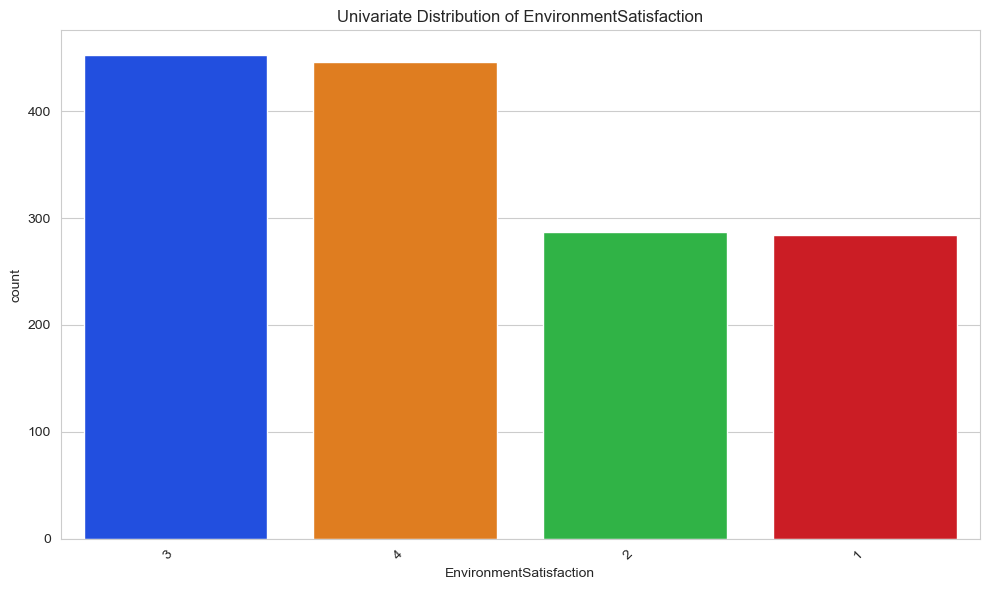

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


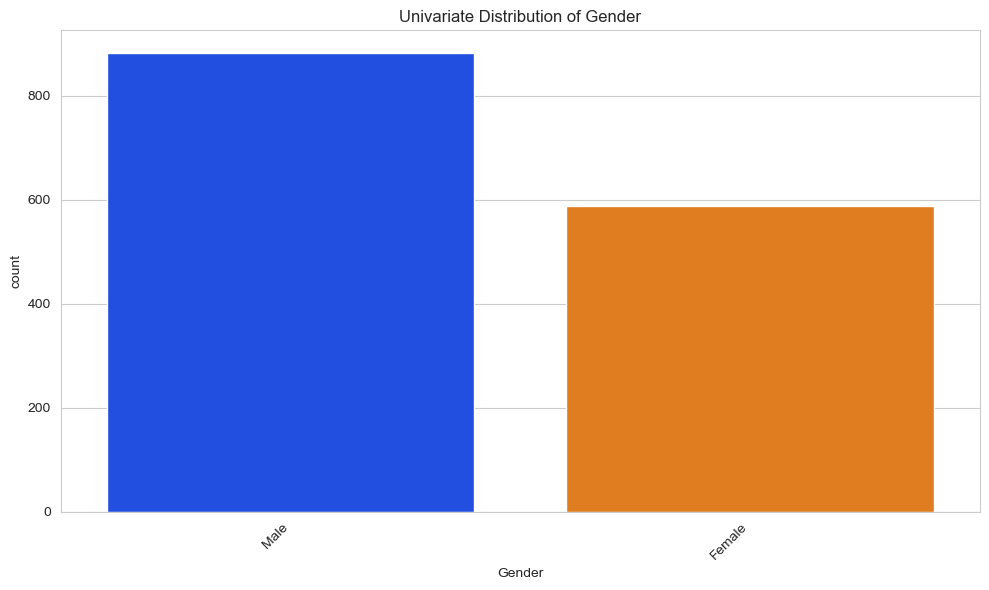

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


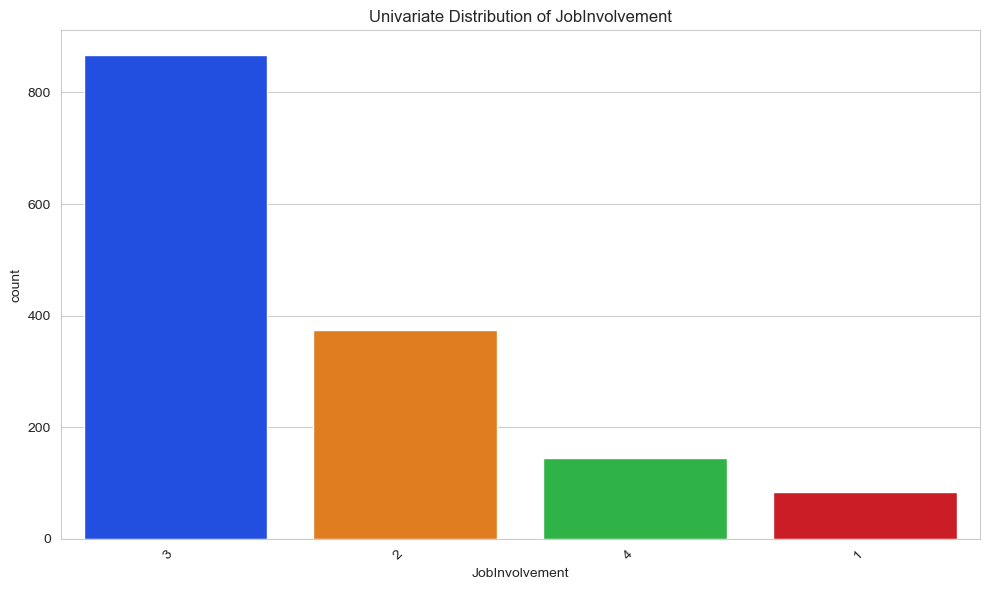

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


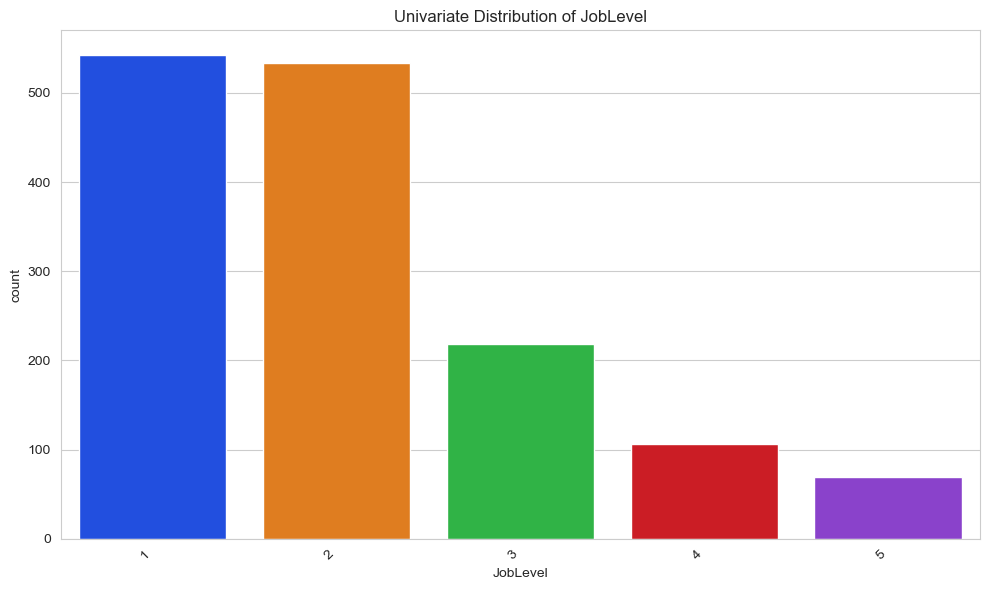

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


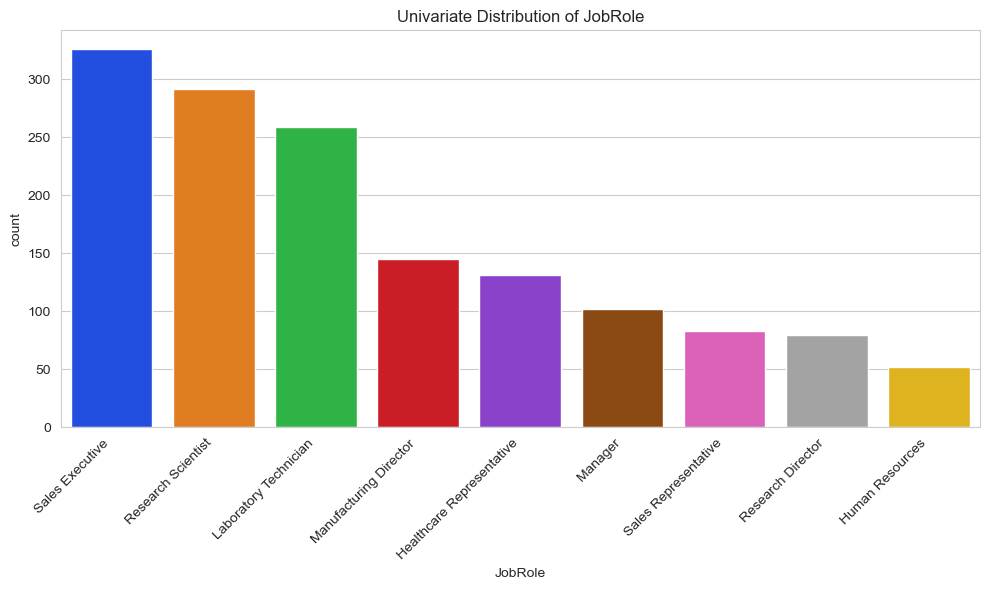

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


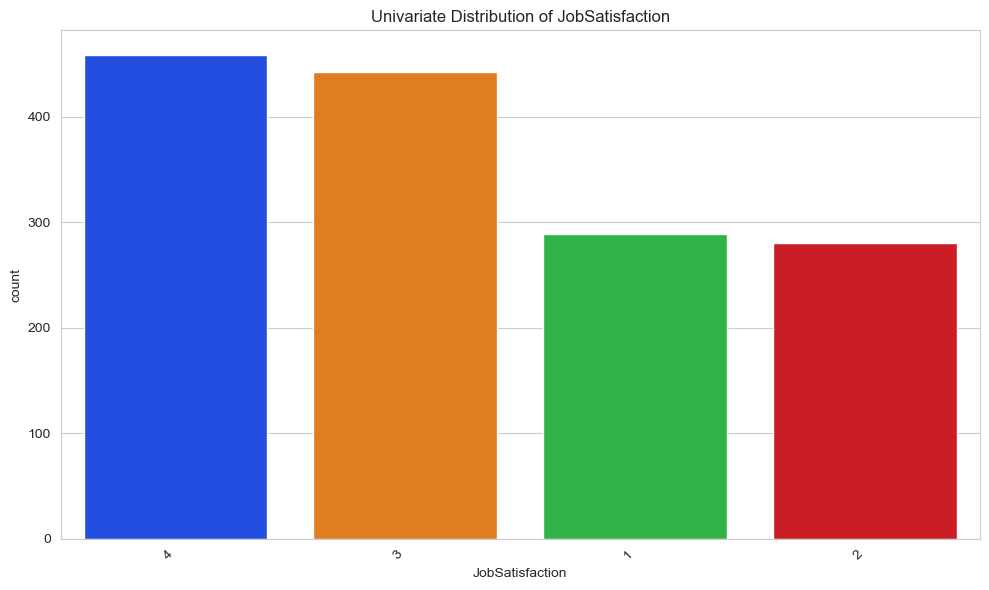

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


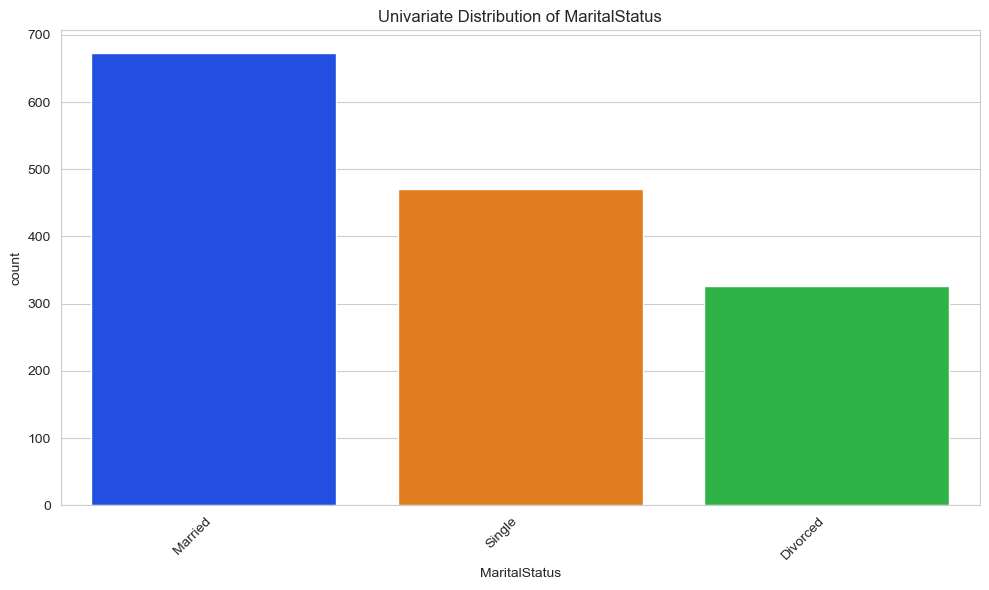

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


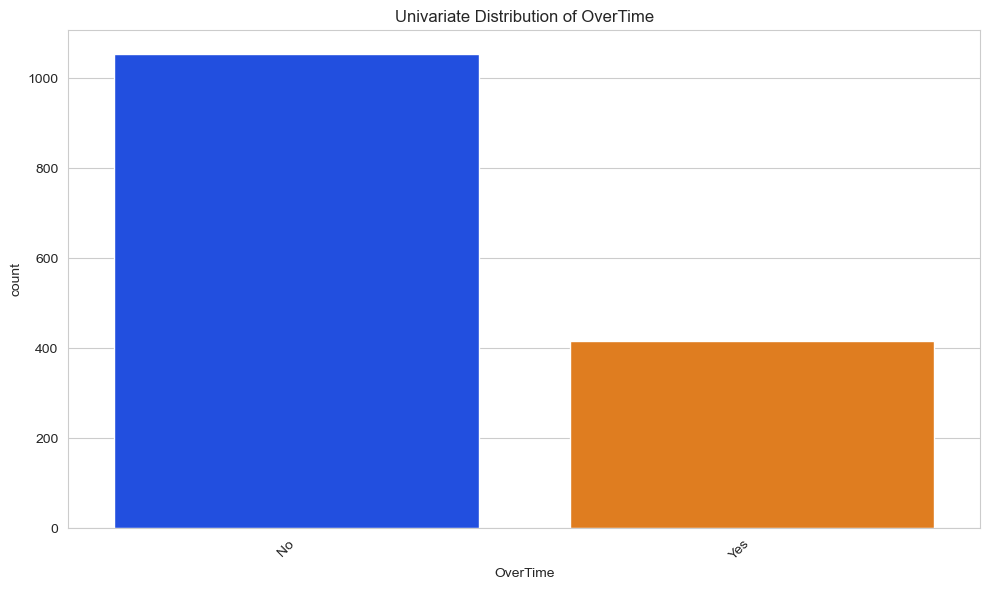

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


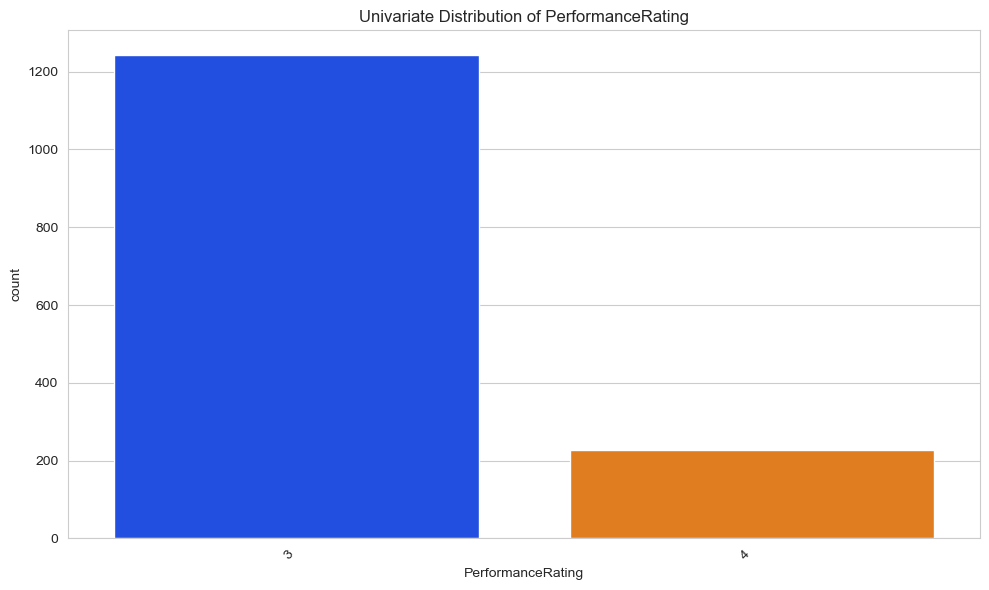

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


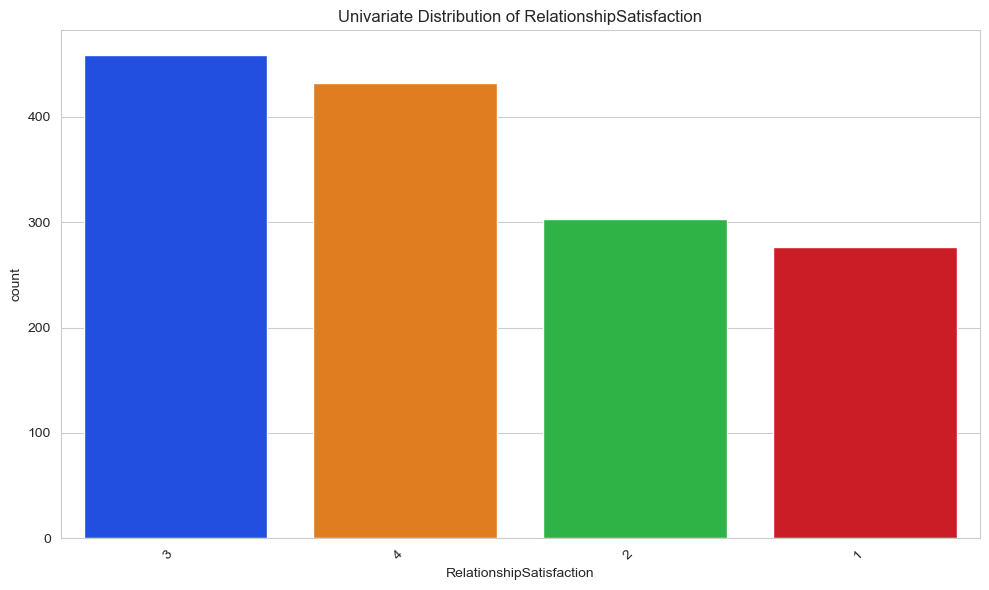

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


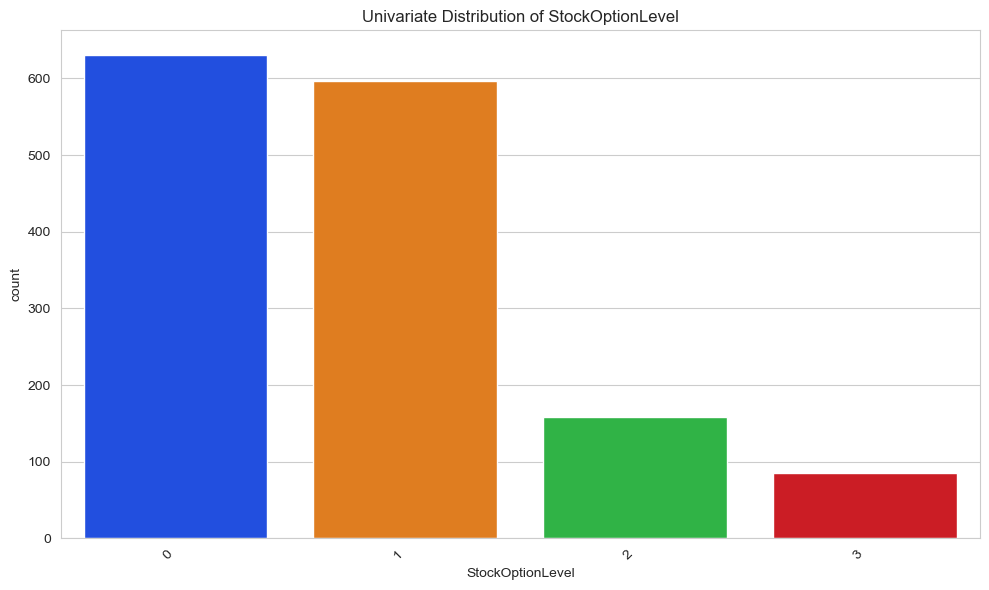

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


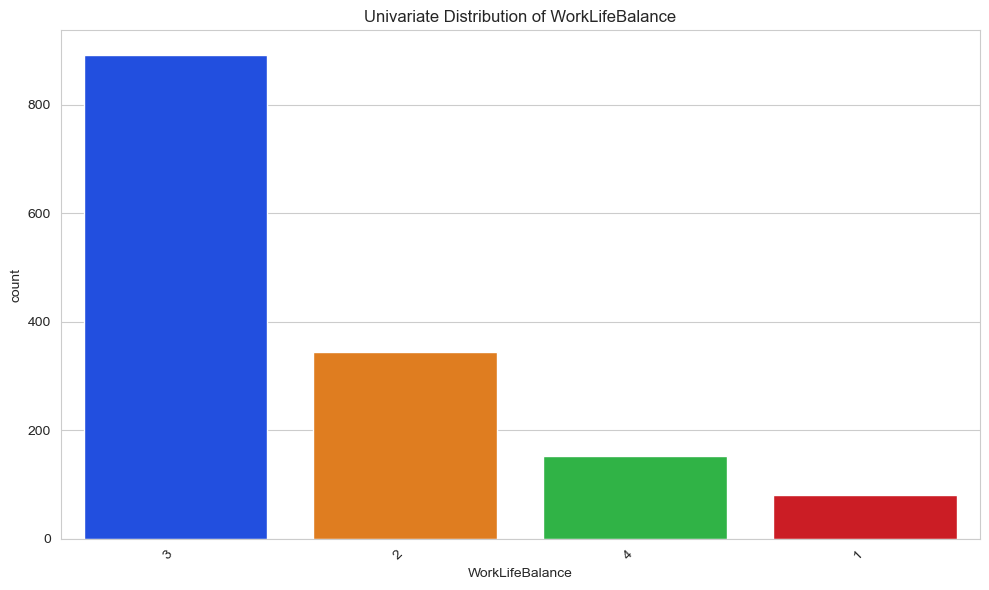

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


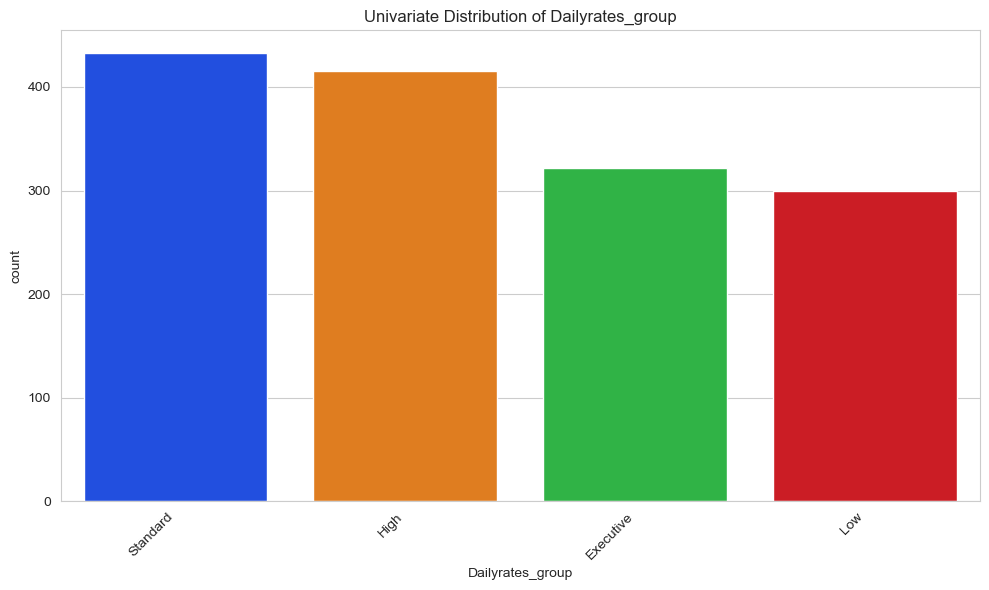

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


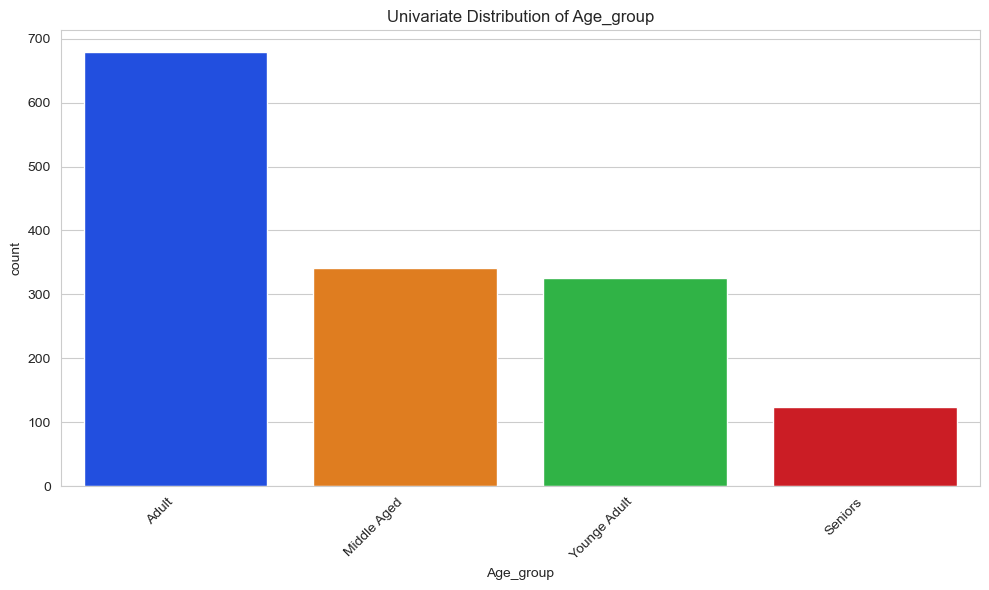

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


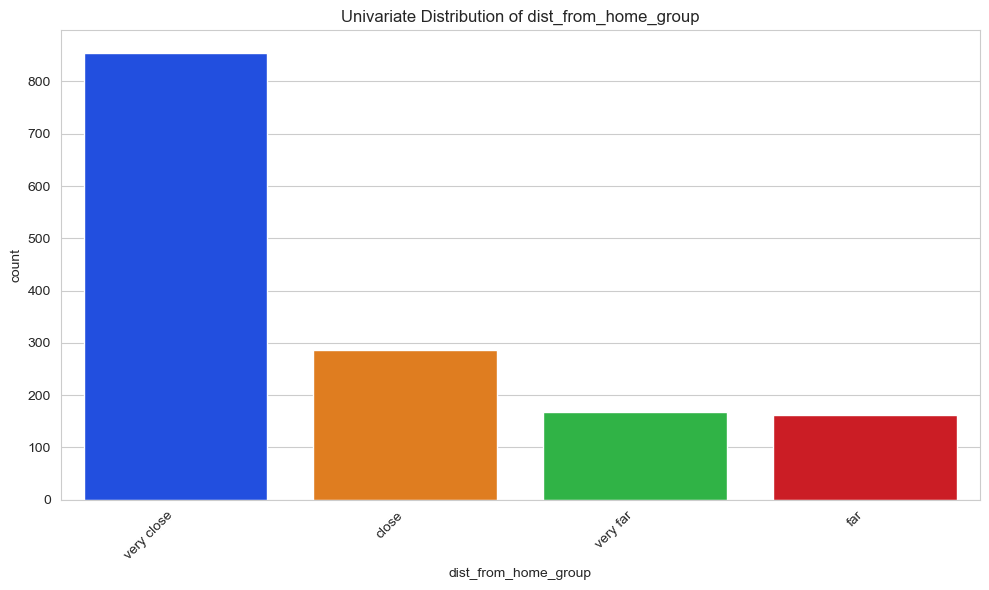

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


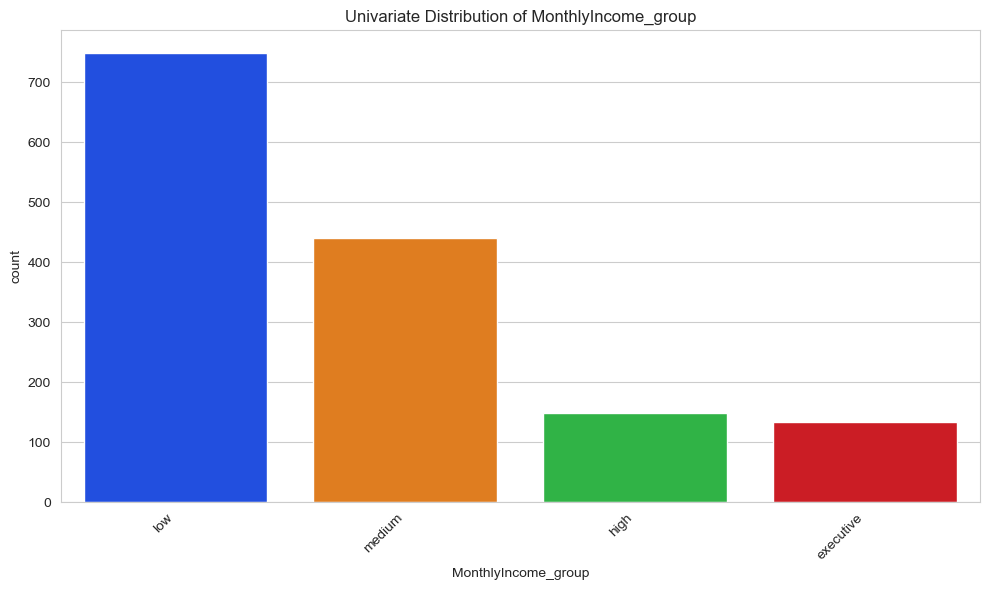

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


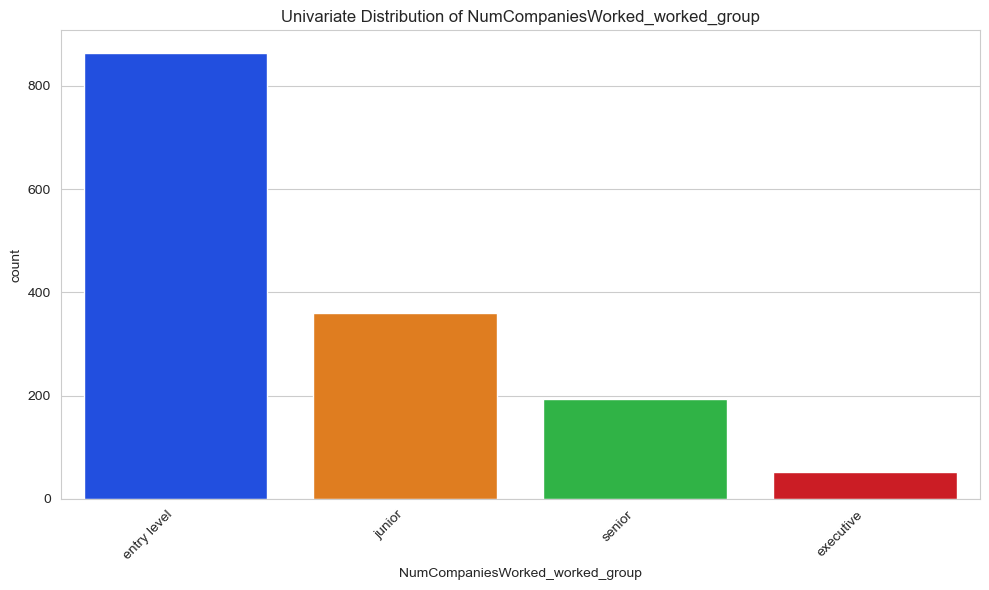

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


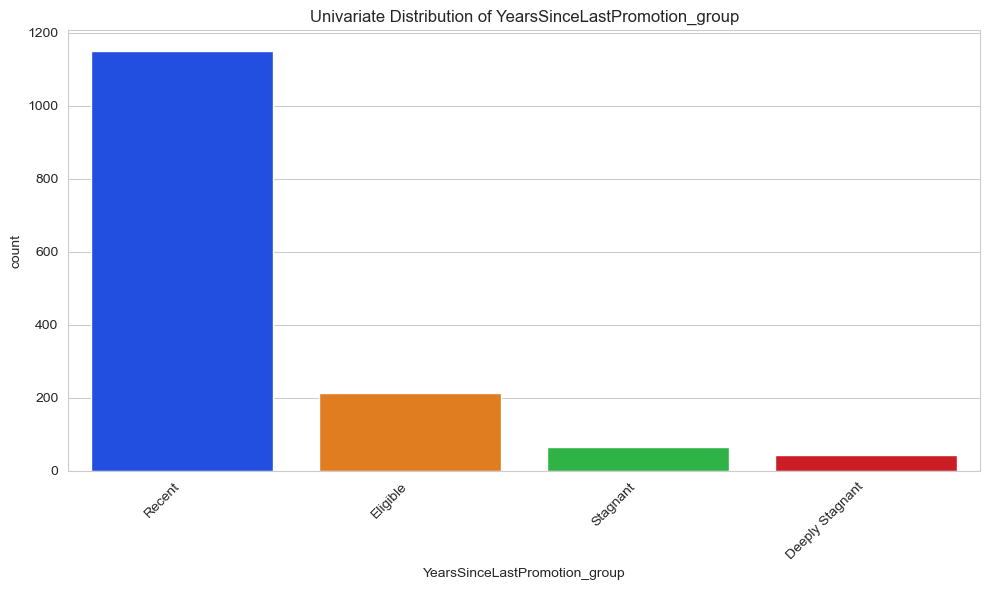

C:\Users\User\AppData\Local\Temp\ipykernel_14940\3466253265.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


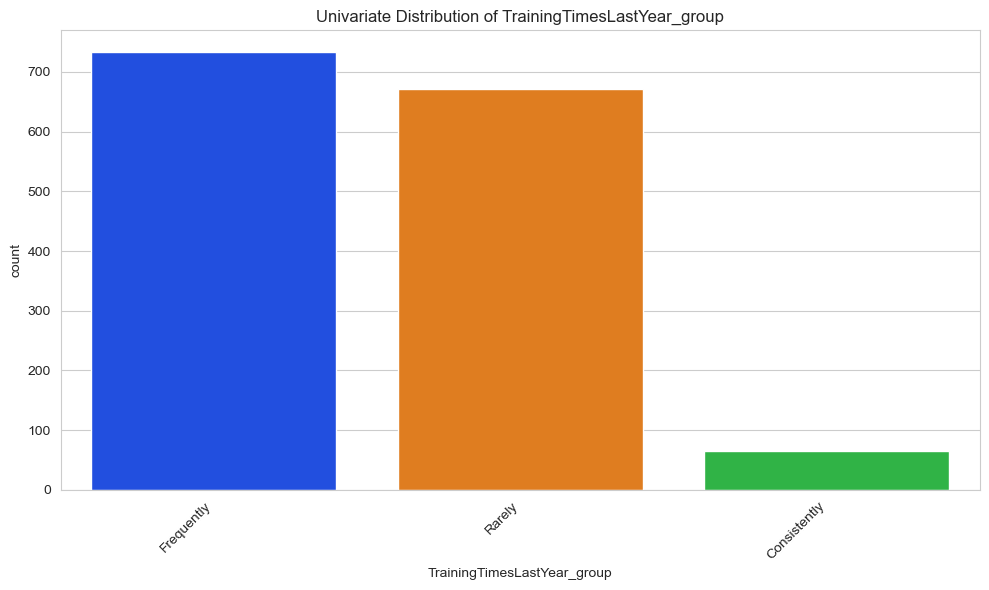

In [26]:
# Loop through and plot each categorical column while automatically filtering out numerical columns, keeping only categorical/object columns
categorical_columns = dfs.select_dtypes(include=['object', 'category']).columns


for col_name in categorical_columns:
    uniplot(
        dfs=dfs, 
        col=col_name, 
        title=f'Univariate Distribution of {col_name}'
    )

# Numeric Analysis

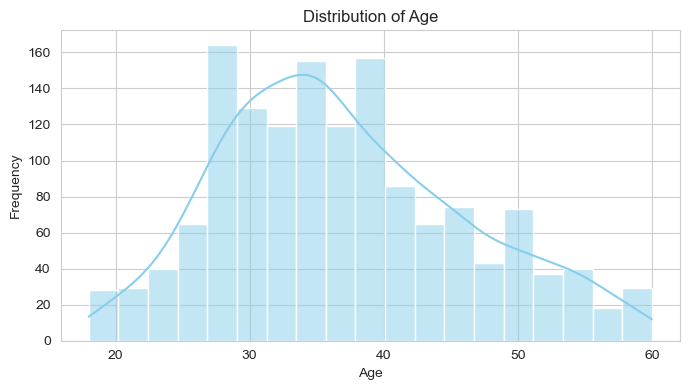

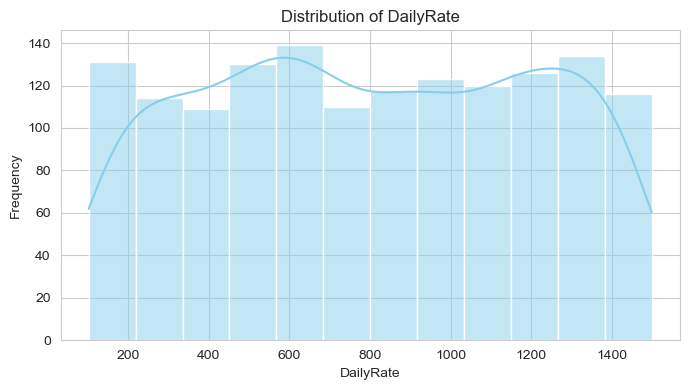

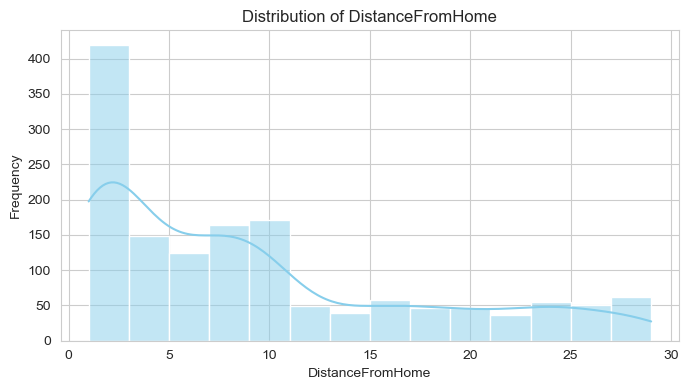

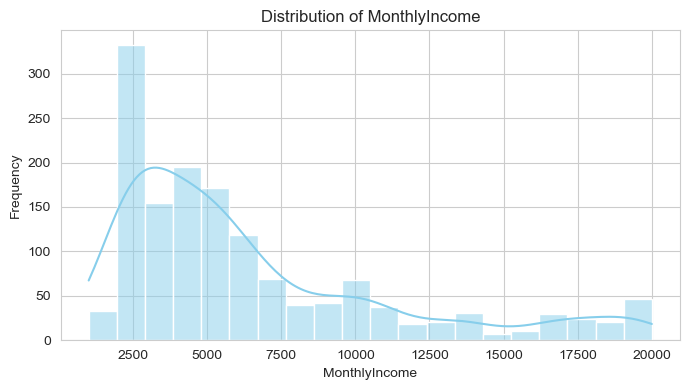

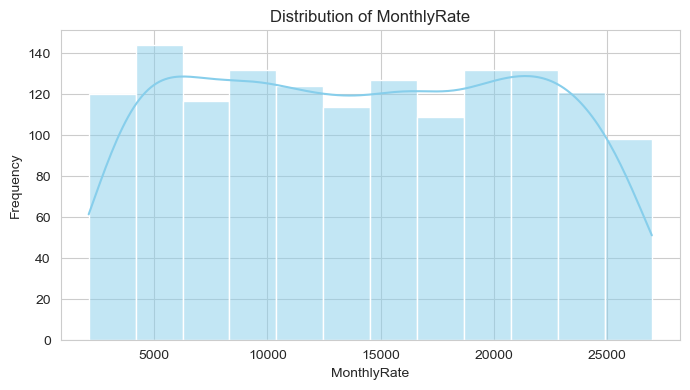

...

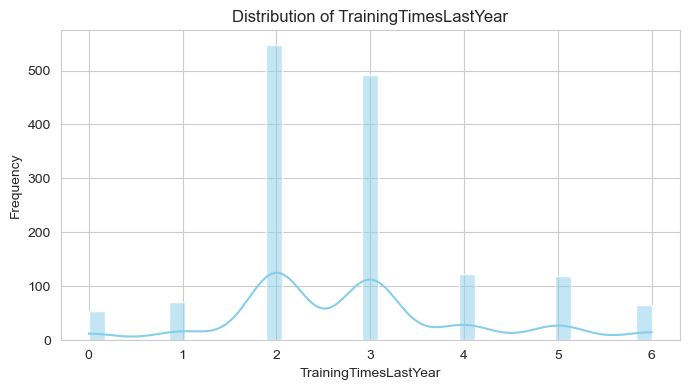

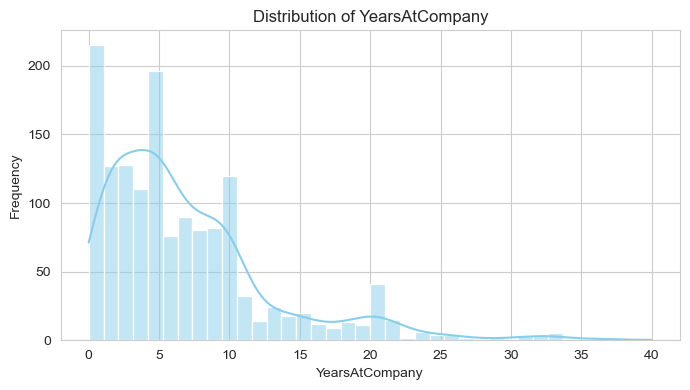

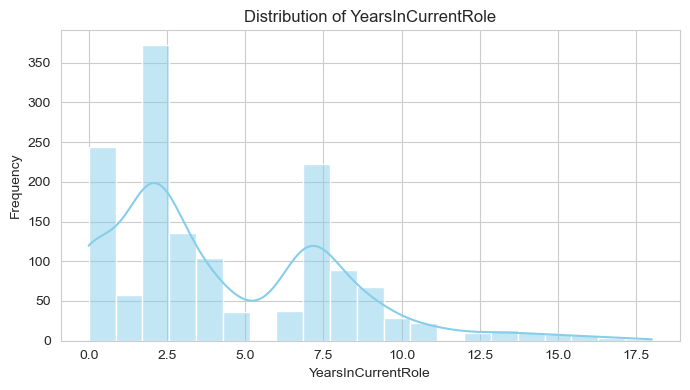

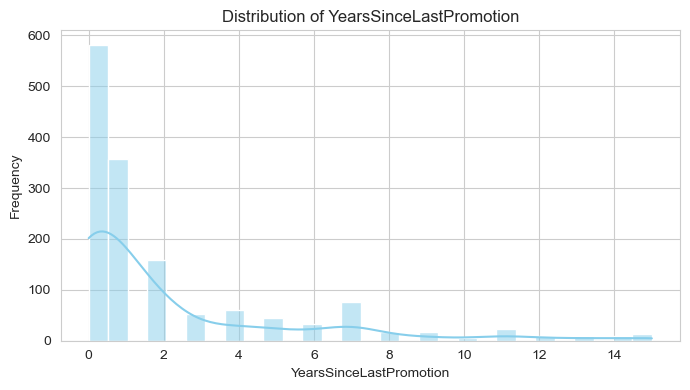

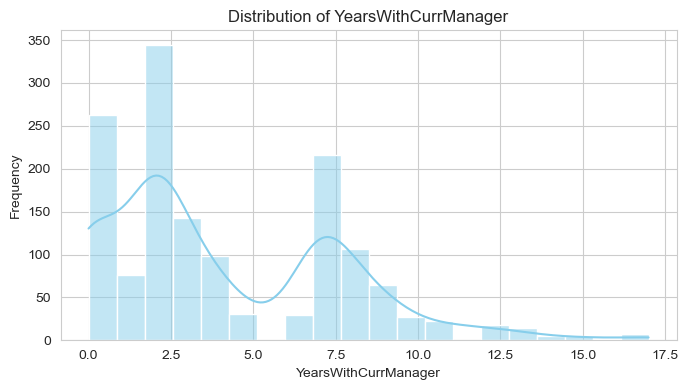

In [27]:
# Plotting the statistical distribution of the numerical features

# Define your list of numeric columns
numeric_cols = [
    'Age', 'DailyRate', 'DistanceFromHome', 'MonthlyIncome', 'MonthlyRate', 
    'NumCompaniesWorked', 'PercentSalaryHike', 'StandardHours', 
    'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager'
]

# Loop through each numeric feature and plot its distribution
for col in numeric_cols:
    fig, ax = plt.subplots(figsize=(7, 4))
    
    # Histplot with an overlaid KDE curve
    sns.histplot(data=dfc, x=col, kde=True, ax=ax, color='skyblue')
    
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()
    
    # Close figure to prevent memory warnings
    plt.close(fig)

- this shows our numeric columns are highly skewed

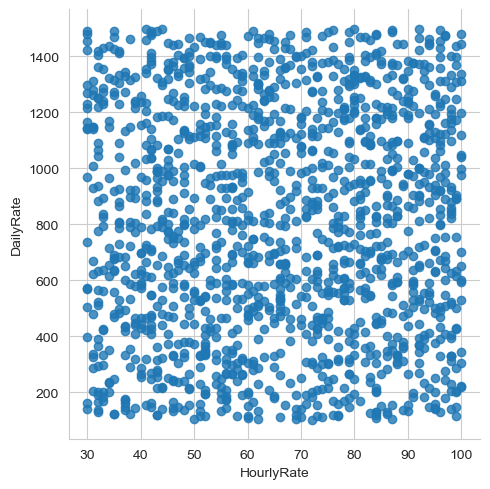

In [28]:
# Relationship between hourly rate and daily rate

sns.lmplot(data=dfs,x='HourlyRate',y='DailyRate', fit_reg= False)

- no relationship between hourly rate and daily rate

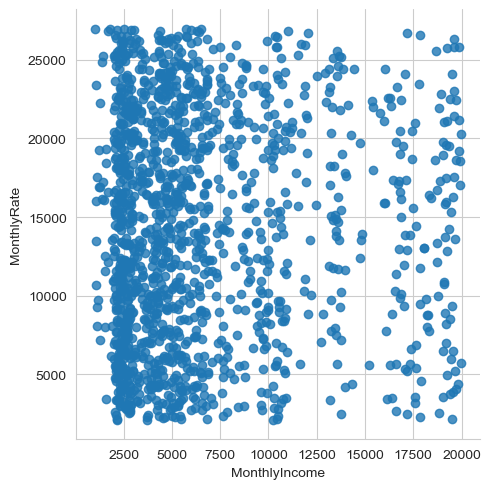

In [29]:
sns.lmplot(data=dfs,x='MonthlyIncome',y='MonthlyRate', fit_reg=False)

- no relationship between monthly rate and monthly income

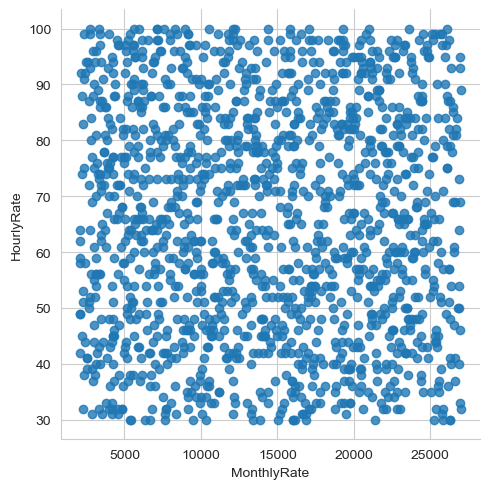

In [30]:
sns.lmplot(data=dfs,x='MonthlyRate',y='HourlyRate', fit_reg=False)

- no relationship between hourly rate and monthly rate

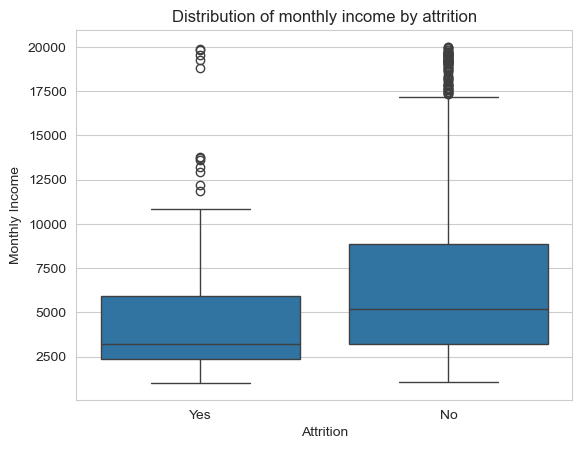

              25%     50%     75%
Attrition                        
No         3211.0  5204.0  8834.0
Yes        2373.0  3202.0  5916.0


In [31]:
# Distribution of monthly income by attrition

dist_mnth_inc= sns.boxplot(data= dfc, x='Attrition', y= 'MonthlyIncome')
plt.title('Distribution of monthly income by attrition')
plt.xlabel('Attrition')
plt.ylabel('Monthly Income')
plt.show()

percentiles_values= dfc.groupby('Attrition')['MonthlyIncome'].describe()[['25%','50%','75%']]
print(percentiles_values)

- The average monthly income of staff who leave the company is ~38% lower than that of retained staff at ~4787.09%
- while 75% of them earn ~5916.0($) which is slightly above mean monthly salary of retained staffs ~5204.0
- hence, low salary is one of the reasons for attrition

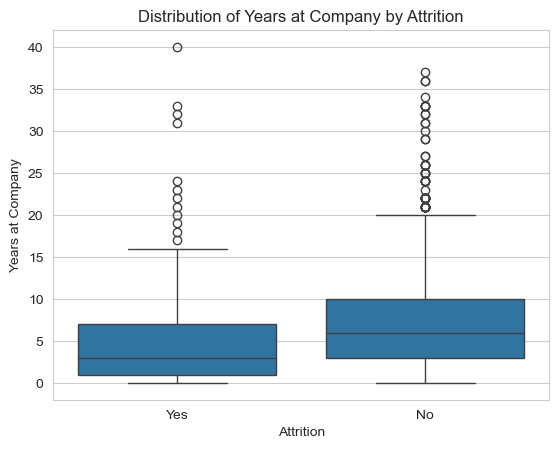

           25%  50%   75%
Attrition                
No         3.0  6.0  10.0
Yes        1.0  3.0   7.0


In [32]:
# Distribution of years at company by attrition

sns.boxplot(data=dfc, x='Attrition', y='YearsAtCompany')
plt.title('Distribution of Years at Company by Attrition')
plt.xlabel('Attrition')
plt.ylabel('Years at Company')
plt.show()

att_YearsAtCompany= dfc.groupby('Attrition')['YearsAtCompany'].describe()[['25%', '50%', '75%']]
print(att_YearsAtCompany)

- Half of the people who leave the company spend 3 years
- Half of the staff thereby spend 50% fewer years at the company 

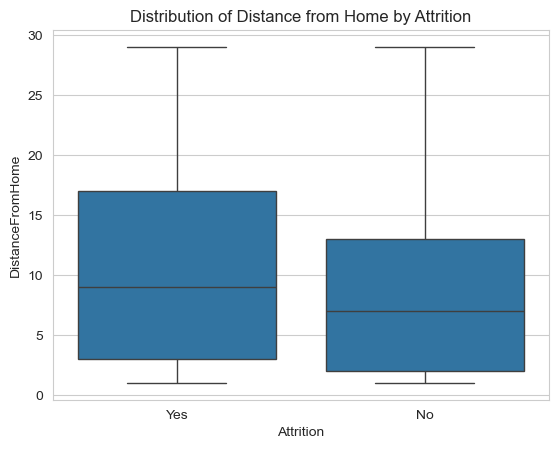

           25%  50%   75%
Attrition                
No         2.0  7.0  13.0
Yes        3.0  9.0  17.0


In [33]:
# Distribution of distance from home by attrition

sns.boxplot(data= dfc, x='Attrition', y= 'DistanceFromHome')
plt.title('Distribution of Distance from Home by Attrition')
plt.show()

att_YearsAtCompany=dfc.groupby('Attrition')['DistanceFromHome'].describe()[['25%', '50%', '75%']]
print(att_YearsAtCompany)

- Half of the staff cover 29% more travel time/distance to get work
- They are people that come from father distances

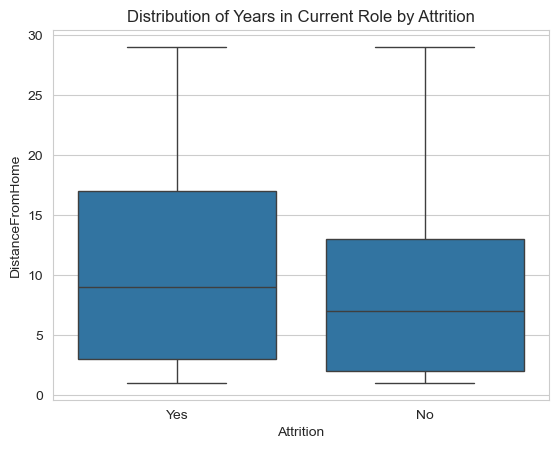

           25%  50%  75%
Attrition               
No         2.0  3.0  7.0
Yes        0.0  2.0  4.0


In [34]:
# Distribution of distance from home by attrition

sns.boxplot(data= dfc, x='Attrition', y= 'DistanceFromHome')
plt.title('Distribution of Years in Current Role by Attrition')
plt.show()

att_YearsInCurrentRole = dfc.groupby('Attrition')['YearsInCurrentRole'].describe()[['25%', '50%', '75%']]
print(att_YearsInCurrentRole)

- 25% of staffs that leave do not spend up to 1 year in their current role
- While of staffs that leave donot stay for more than 2 years in their current role
- These means that staffs desire for growth/promotion

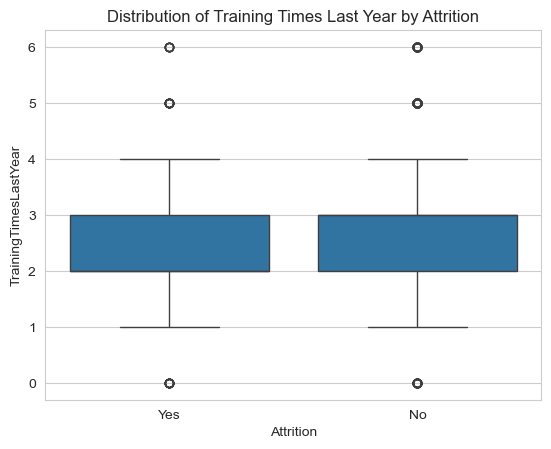

           25%  50%  75%
Attrition               
No         2.0  3.0  3.0
Yes        2.0  2.0  3.0


In [35]:
# Distribution of distance from home by attrition

sns.boxplot(data= dfc, x='Attrition', y= 'TrainingTimesLastYear')
plt.title('Distribution of Training Times Last Year by Attrition')
plt.show()

att_TrainingTimesLastYear = dfc.groupby('Attrition')['TrainingTimesLastYear'].describe()[['25%', '50%', '75%']]
print(att_TrainingTimesLastYear)

- 50% of people that leave donot attend more than 2 training sessions which is ~30 fewer than those who ramain

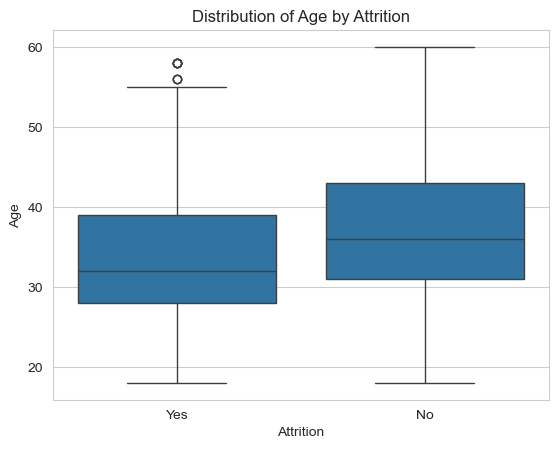

            25%   50%   75%
Attrition                  
No         31.0  36.0  43.0
Yes        28.0  32.0  39.0


In [36]:
# Distribution of distance from home by attrition

sns.boxplot(data= dfc, x='Attrition', y= 'Age')
plt.title('Distribution of Age by Attrition')
plt.show()

att_Age = dfc.groupby('Attrition')['Age'].describe()[['25%', '50%', '75%']]
print(att_Age)

- younger staffs tend to leave more than older ones

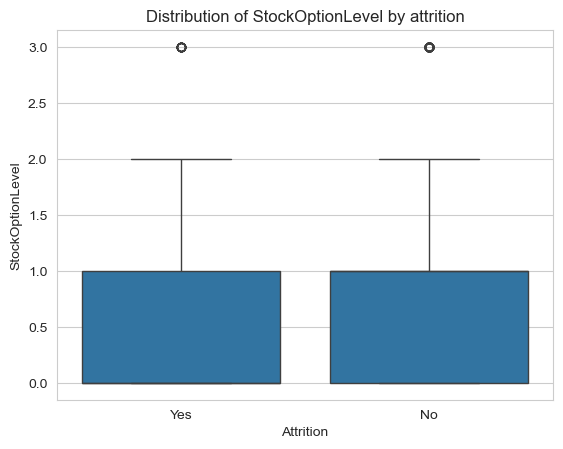

           25%  50%  75%
Attrition               
No         0.0  1.0  1.0
Yes        0.0  0.0  1.0


In [37]:
# Distribution of age by attrition

sns.boxplot(data= dfc, x= 'Attrition',y='StockOptionLevel')
plt.title('Distribution of StockOptionLevel by attrition')
plt.show()

att_StockOptionLevel= dfc.groupby('Attrition')['StockOptionLevel'].describe()[['25%','50%', '75%']]
print(att_StockOptionLevel)                                                     


- Half the staff existing have no stockoptions

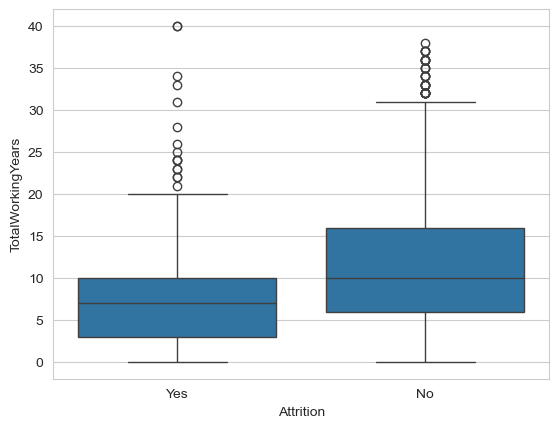

           25%   50%   75%
Attrition                 
No         6.0  10.0  16.0
Yes        3.0   7.0  10.0


In [38]:
# Distribution of Attrition by Total Working Years

sns.boxplot(data= dfc,x='Attrition', y='TotalWorkingYears')
plt.title= 'Distribution of Attrition by Total Working Years'
plt.show()

att_TotalWorkingYears= dfc.groupby('Attrition')['TotalWorkingYears'].describe()[['25%', '50%','75%']]
print(att_TotalWorkingYears)

- 25% of existed staffs have only worked for 3 years (50% fewer than those that stayed) while 75% of them account for not more than 10 years (38% fewer than those that stayed)

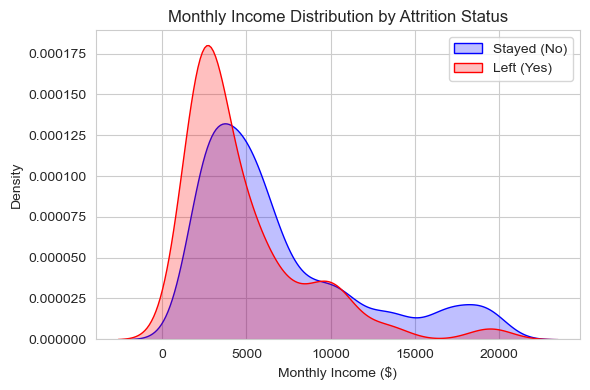

In [39]:
# Monthly income distribution by attrition

fig, ax = plt.subplots(figsize=(6, 4))
sns.kdeplot(
    data=dfc[dfc['Attrition'] == 'No'], 
    x='MonthlyIncome', 
    color='Blue', 
    fill=True, 
    label='Stayed (No)', 
    ax=ax
)

sns.kdeplot(
    data=dfc[dfc['Attrition'] == 'Yes'], 
    x='MonthlyIncome', 
    color='Red', 
    fill=True, 
    label='Left (Yes)', 
    ax=ax
)

ax.set_title('Monthly Income Distribution by Attrition Status')
ax.set_xlabel('Monthly Income ($)')
ax.set_ylabel('Density')
ax.legend()

plt.tight_layout()
plt.show()
plt.close(fig)

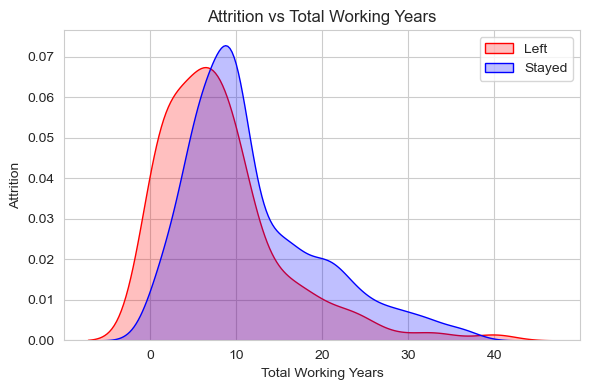

In [40]:
# Total working years distribution by attrition

fig, ax= plt.subplots(figsize=(6,4))
sns.kdeplot(data=dfc[dfc['Attrition']=='Yes'], x= 'TotalWorkingYears', color= 'Red', fill=True, label= 'Left', ax=ax)
sns.kdeplot(data= dfc[dfc['Attrition']=='No'], x= 'TotalWorkingYears', color= 'Blue',fill= True, label= 'Stayed', ax=ax)
ax.set_title( 'Attrition vs Total Working Years')
ax.set_xlabel('Total Working Years')
ax.set_ylabel('Attrition')
ax.legend()

plt.tight_layout()
plt.show()

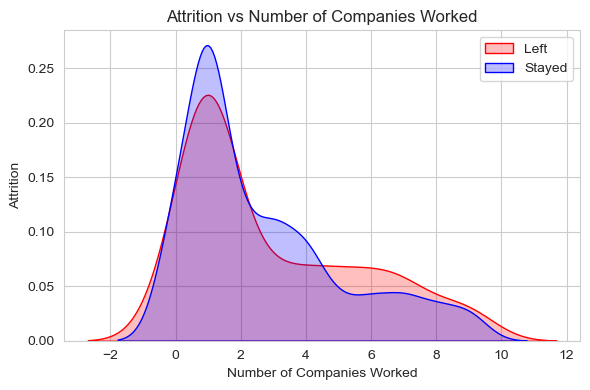

In [41]:
# Number of companies worked distribution by attrition

fig, ax= plt.subplots(figsize=(6,4))
sns.kdeplot(
    data= dfc[dfc['Attrition']=='Yes'], 
    x= 'NumCompaniesWorked', 
    color='Red', 
    fill= True, 
    label= 'Left',
    ax=ax
)

sns.kdeplot(
    data= dfc[dfc['Attrition']=='No'],
    x= 'NumCompaniesWorked',
    color='Blue',
    fill= True,
    label='Stayed',
    ax=ax
)

ax.set_title('Attrition vs Number of Companies Worked')
ax.set_xlabel('Number of Companies Worked')
ax.set_ylabel('Attrition')
ax.legend()

plt.tight_layout()
plt.show()

- KDE plot of monthly income also show that most staffs that exit are low earners
- Tenure plot also show that about 75% of exiting staffs do not stay for more than 10 years
- While work experience distribution shows that company tends to hire more of fresh graduate and majority of exiting staff are from that category as well


Attrition                   No        Yes
MonthlyIncome_group                      
low                  78.237650  21.762350
medium               88.863636  11.136364
high                 86.486486  13.513514
executive            96.240602   3.759398


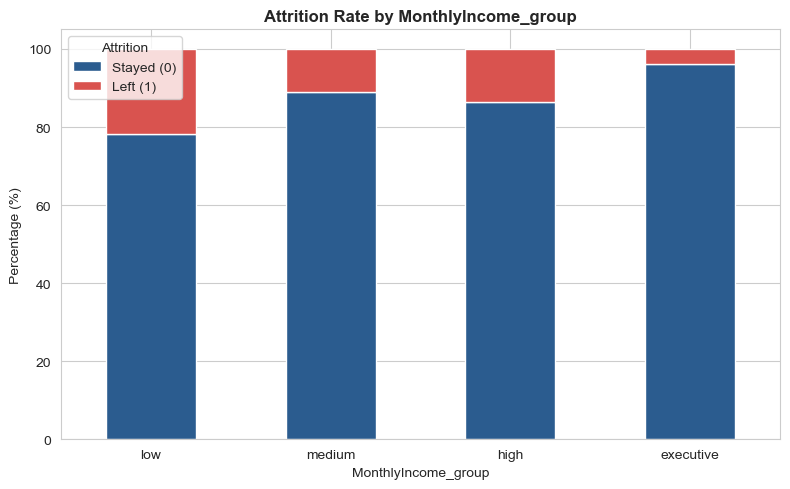

In [42]:
# Attrition rate by monthly income groups

income_crosstab = pd.crosstab(dfs['MonthlyIncome_group'], dfc['Attrition'], normalize='index') * 100
print(income_crosstab)
fig, ax = plt.subplots(figsize=(8, 5))
income_crosstab.plot(kind='bar', stacked=True, color=['#2b5c8f', '#d9534f'], ax=ax)

ax.set_title('Attrition Rate by MonthlyIncome_group', fontsize=12, fontweight='bold')
ax.set_xlabel('MonthlyIncome_group', fontsize=10)
ax.set_ylabel('Percentage (%)', fontsize=10)
ax.legend(['Stayed (0)', 'Left (1)'], title='Attrition')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()
plt.close(fig)

# Multivariate Analysis

In [43]:
# Converting attrition to binary

dfs['Attrition']= np.where(dfs['Attrition']=='Yes',1,0)

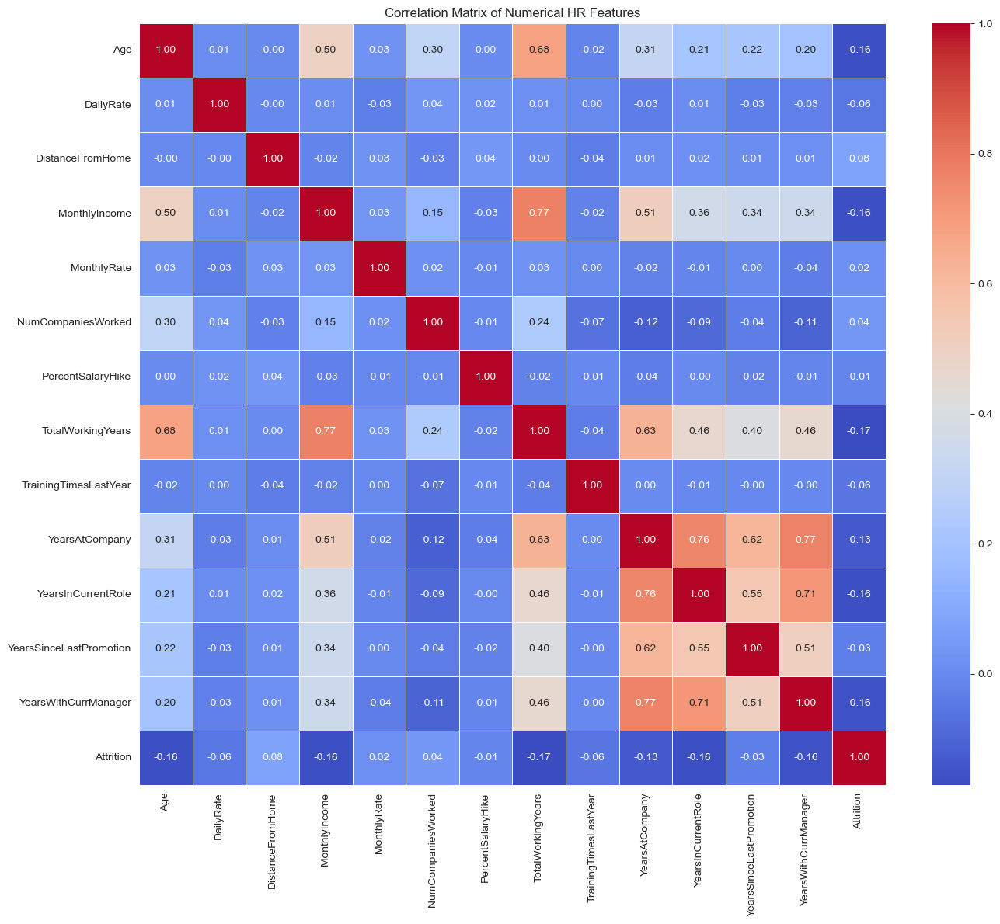

In [44]:
# Heatmap of the dataset

numeric_cols= ['Age', 'DailyRate', 'DistanceFromHome', 'MonthlyIncome', 'MonthlyRate', 
  'NumCompaniesWorked', 'PercentSalaryHike', 
    'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 
    'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager','Attrition'
]

corr_matrix = dfs[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    linewidths=0.5, 
    ax=ax
)

ax.set_title('Correlation Matrix of Numerical HR Features')
plt.tight_layout()
plt.show()
plt.close(fig)

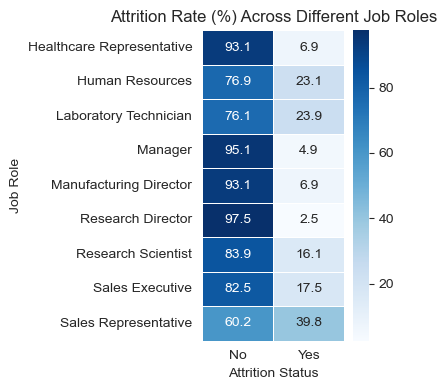

In [45]:
# 1. Rate of attrition acroos JobRole
cat_crosstab = pd.crosstab(dfc['JobRole'], dfc['Attrition'], normalize='index') * 100 
fig, ax = plt.subplots(figsize=(4, 4))
sns.heatmap(
    cat_crosstab, 
    annot=True, 
    fmt='.1f', 
    cmap='Blues', 
    linewidths=0.5, 
    ax=ax
)

ax.set_title('Attrition Rate (%) Across Different Job Roles')
ax.set_xlabel('Attrition Status')
ax.set_ylabel('Job Role')

plt.tight_layout()
plt.show()
plt.close(fig)

- sales representative, laboratory technician, human resources, sale excutive, research scientist job roles respectively tends to leave the company.

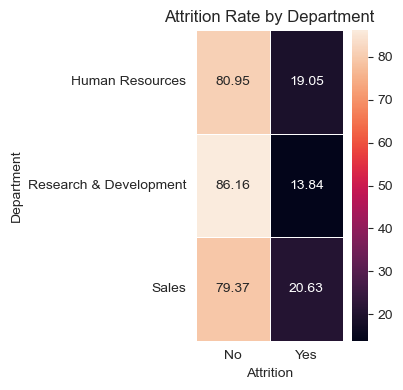

In [46]:
# Rate of attrition acroos departments

crosstab_dept= pd.crosstab(dfc['Department'],dfc['Attrition'],normalize= 'index')*100

fig, ax= plt.subplots(figsize=(4,4))

sns.heatmap(
    crosstab_dept,
    annot= True,
    fmt= '.2f',
    linewidths= 0.5,
    ax=ax)
ax.set_title('Attrition Rate by Department')
plt.tight_layout()

- sales and Human Resources departments loss staffs at the highest rate

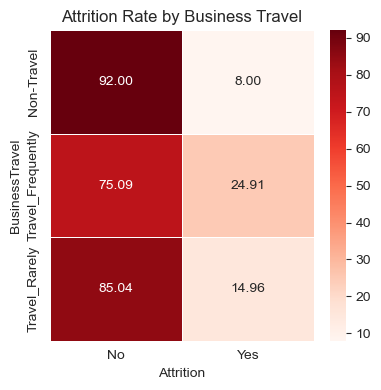

In [47]:
# Rate of attrition acroos Business travel

BusinessTravel_crosstab = pd.crosstab(dfs['BusinessTravel'],dfc['Attrition'], normalize = 'index')*100
fig, ax= plt.subplots(figsize=(4,4))
sns.heatmap(
    BusinessTravel_crosstab,
    cmap= 'Reds',
    annot = True,
    linewidths= .5,
    fmt= '.2f',
    ax=ax
)

ax.set_title('Attrition Rate by Business Travel')

plt.tight_layout()

- staffs that travel frequently are more likely to leave the company

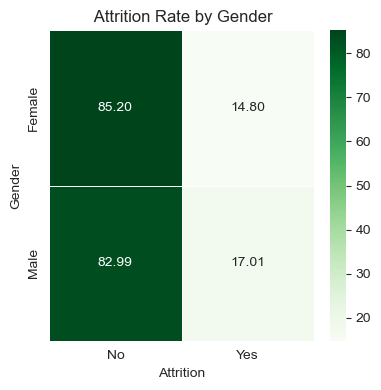

In [48]:
# Rate of attrition acroos Gender

fig, ax = plt.subplots(figsize=(4,4))

Gender_crosstab= pd.crosstab(dfs['Gender'],dfc['Attrition'],normalize='index')*100
sns.heatmap(
    Gender_crosstab,
    cmap= 'Greens',
    fmt='.2f',
    annot= True,
    linewidths= .5,
    ax=ax
)

ax.set_title(' Attrition Rate by Gender')
plt.tight_layout()

- Gender doesn’t show any significant difference between the two. Hence both exit relatively equally


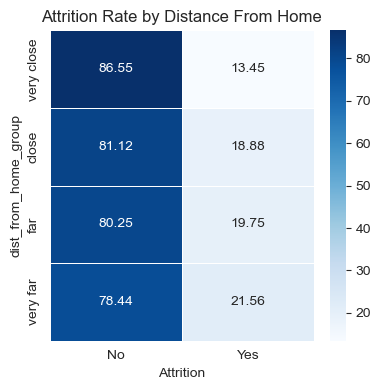

In [49]:
# Rate of attrition acroos distance from home group

crossat_dist_from_home_group= pd.crosstab(dfs['dist_from_home_group'],dfc['Attrition'], normalize= 'index')*100

fig, ax=plt.subplots(figsize=(4,4))
sns.heatmap(
    crossat_dist_from_home_group,
    cmap= 'Blues',
    annot= True,
    fmt= '.2f',
    linewidths=.5,
ax=ax)
ax.set_title('Attrition Rate by Distance From Home')
plt.tight_layout()
    

- staffs that come from far and very far tend to leave the company more than others

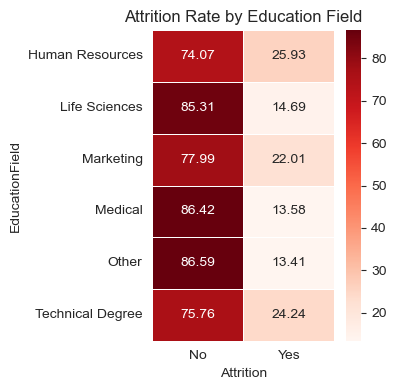

In [50]:
# Rate of attrition acroos education field

EducationField_crosstab= pd.crosstab(dfc['EducationField'],dfc['Attrition'],normalize= 'index')*100

fig, ax= plt.subplots(figsize=(4,4))
sns.heatmap(
    EducationField_crosstab,
    annot= True,
    cmap= 'Reds',
    fmt= '.2f',
    linewidths= .5,
    ax=ax)
ax.set_title( 'Attrition Rate by Education Field')
plt.tight_layout()

- Top 3 Education field with highest attrition includes human resources, marketing and technical degree

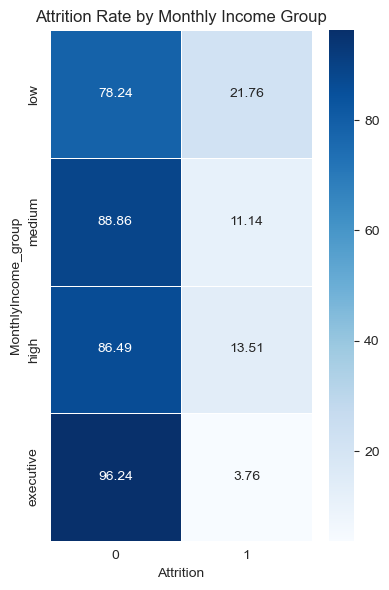

In [51]:
# Rate of attrition acroos monthly income group

crossat_DistanceFromHomeDescription= pd.crosstab(dfs['MonthlyIncome_group'],dfs['Attrition'], normalize= 'index')*100

fig, ax=plt.subplots(figsize=(4,6))
sns.heatmap(
    crossat_DistanceFromHomeDescription,
    cmap= 'Blues',
    annot= True,
    fmt= '.2f',
    linewidths=.5,
ax=ax)
ax.set_title('Attrition Rate by Monthly Income Group')
plt.tight_layout()
    

- Low earners have stronger exit impact

In [52]:
# Creating dummies of the categorical features

dfs_dummies= pd.get_dummies(dfs, dtype=int)

<Axes: >

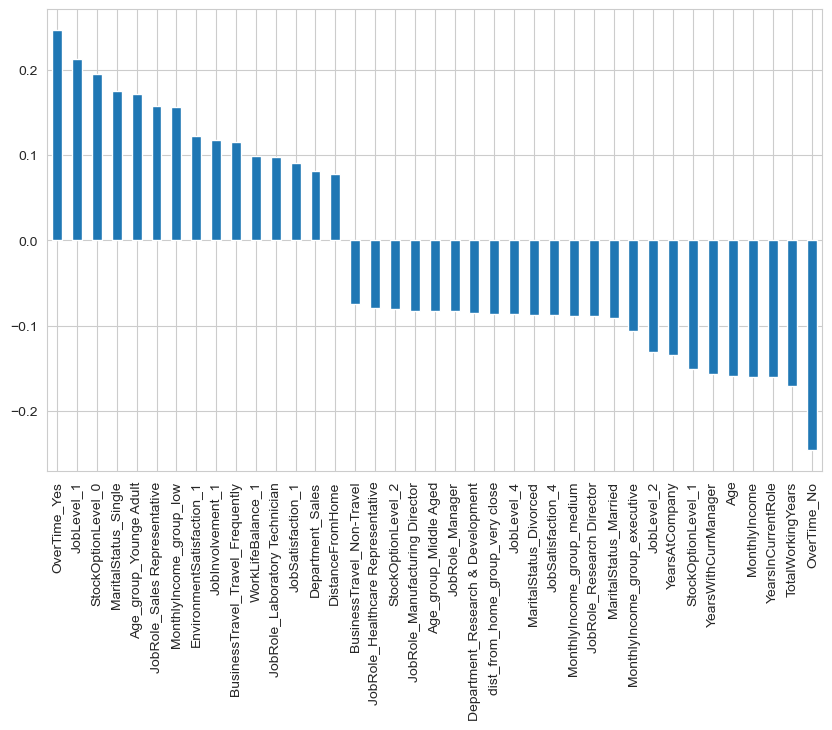

In [53]:
# Determining features that have major impact on attrition

plt.figure(figsize=(10,6))
threshold= .07
corr= dfs_dummies.corr()['Attrition'].drop('Attrition')

corr[corr.abs()>threshold].sort_values(ascending= False).plot(kind='bar')

In [54]:
# Splitting the dataset based o attrition

dfs_1= dfs[dfs['Attrition']==1]
dfs_0= dfs[dfs['Attrition']==0]

In [55]:
# Defining uniplot for multivairate analysis 

def uniplot(dfs, col, title, hue=None):
    sns.set_style('whitegrid')
    sns.set_context('talk')
    n_categories = dfs[col].nunique()
    n_hue = dfs[hue].nunique() if hue is not None else 1
    width = n_categories + 7 + (4 * n_hue)
    
    fig, ax = plt.subplots(figsize=(width, 8))
    sns.countplot(
        data=dfs_1, 
        x=col, 
        order=dfs[col].value_counts().index, 
        hue=hue, 
        palette='bright', 
        ax=ax
    )
    
    plt.xticks(rotation=45, ha='right')
    plt.yscale('log')
    ax.set_title(title)
    
    plt.tight_layout()
    plt.show()
    plt.close(fig)

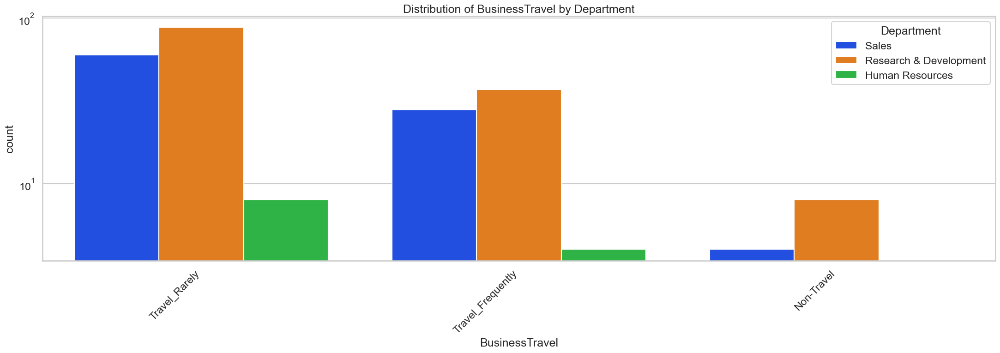

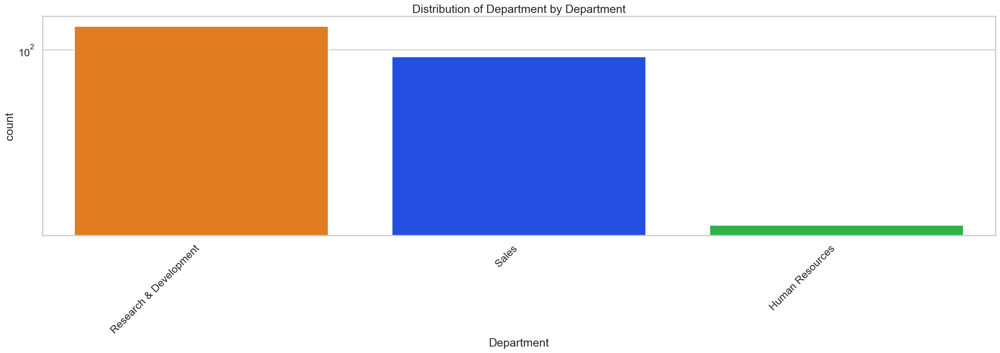

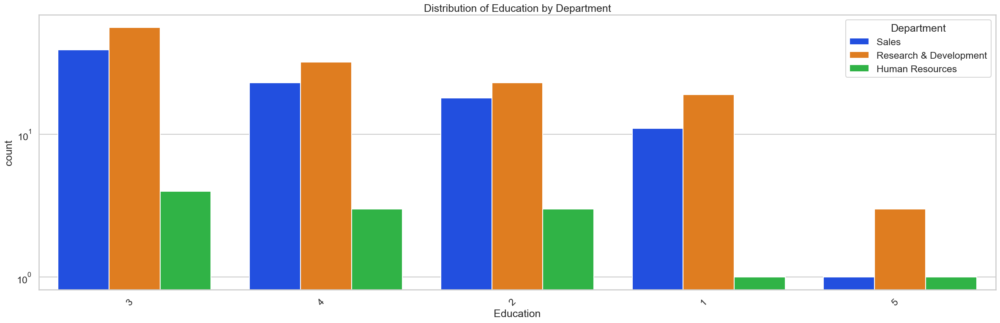

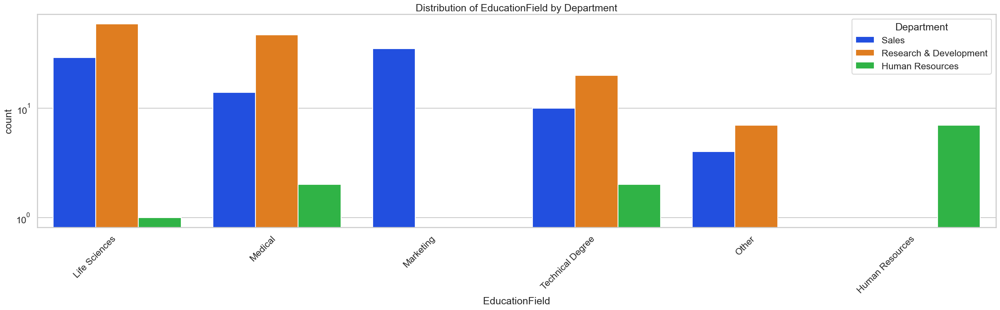

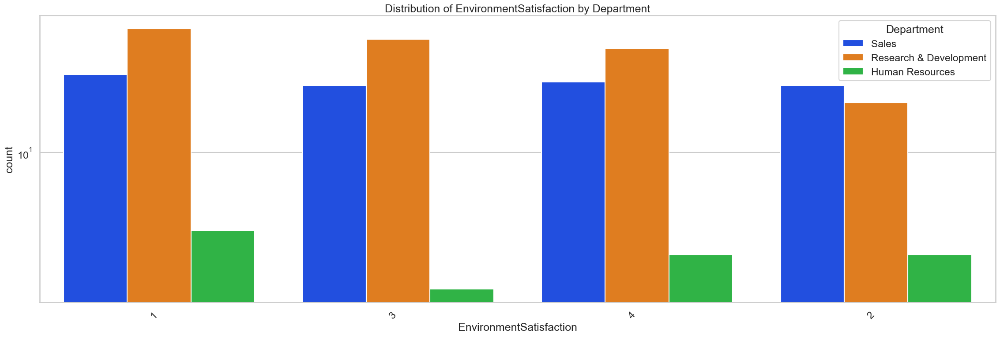

...

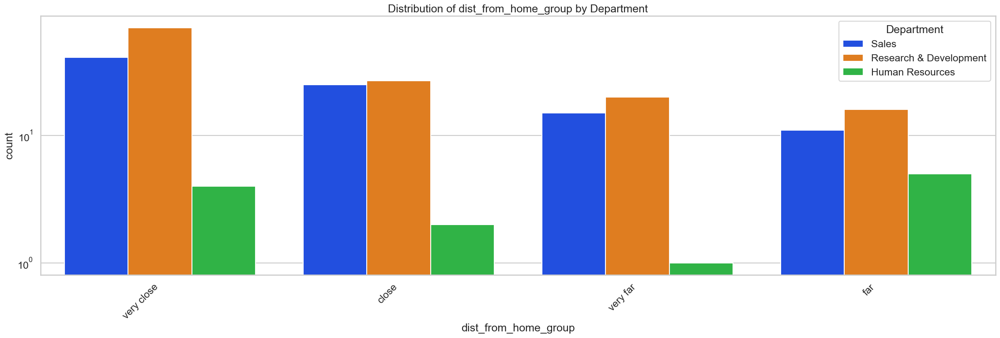

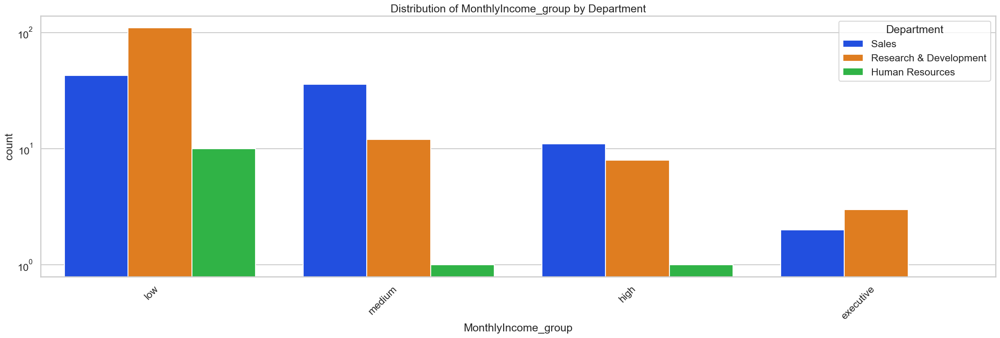

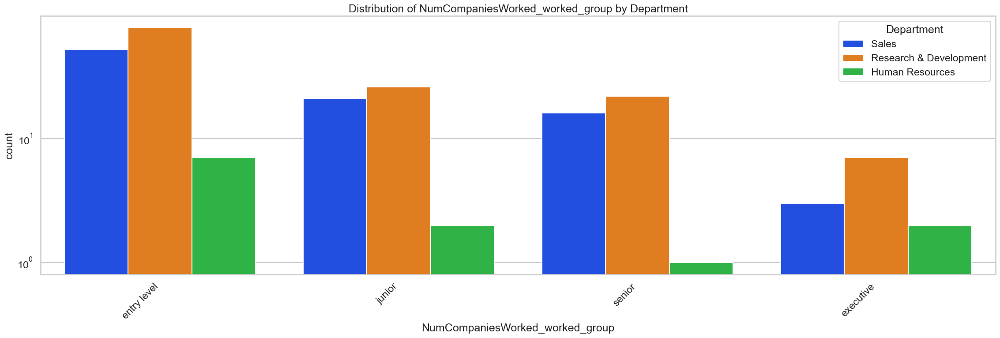

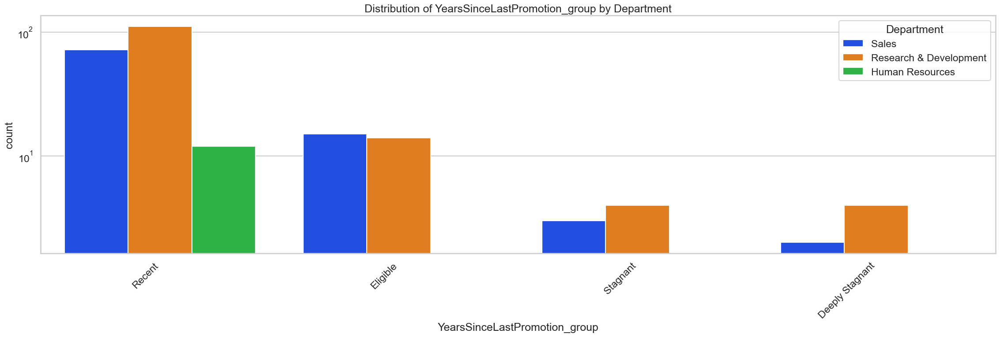

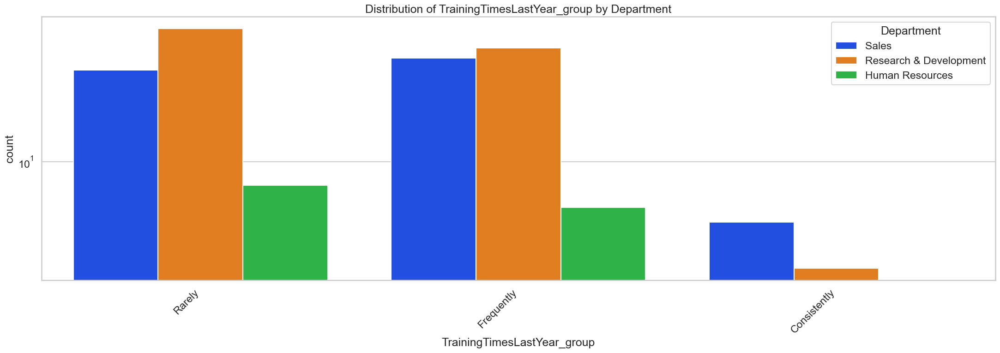

In [56]:
# Define the list of categorical columns you want to plot and plotting them

categorical_columns = dfs_1.select_dtypes(include=['object', 'category']).columns.tolist()
for col_name in categorical_columns:
    uniplot(
        dfs_1, 
        col=col_name, 
        hue='Department', 
        title= f'Distribution of {col_name} by Department'
    )

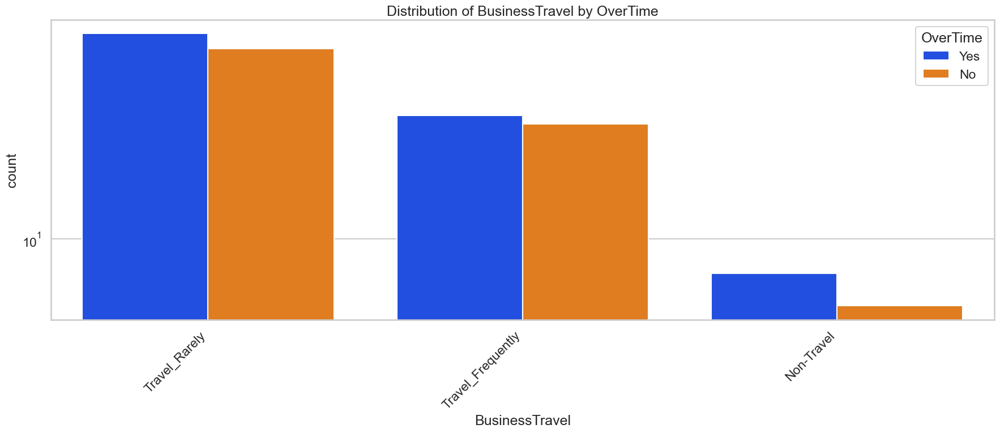

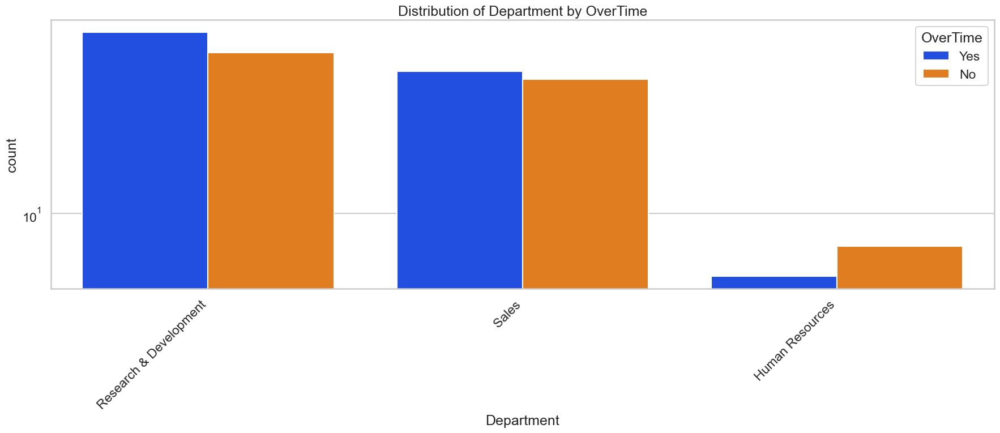

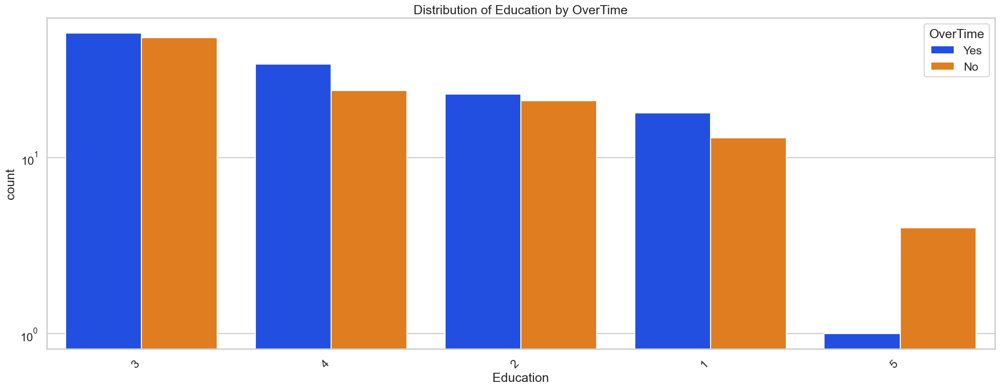

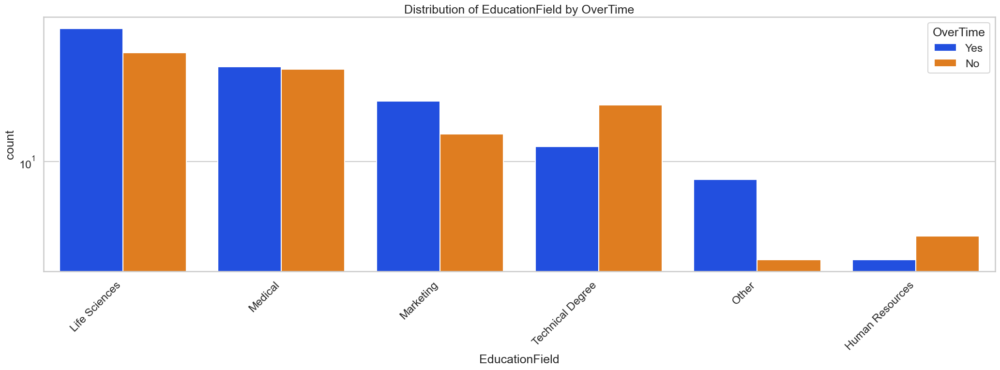

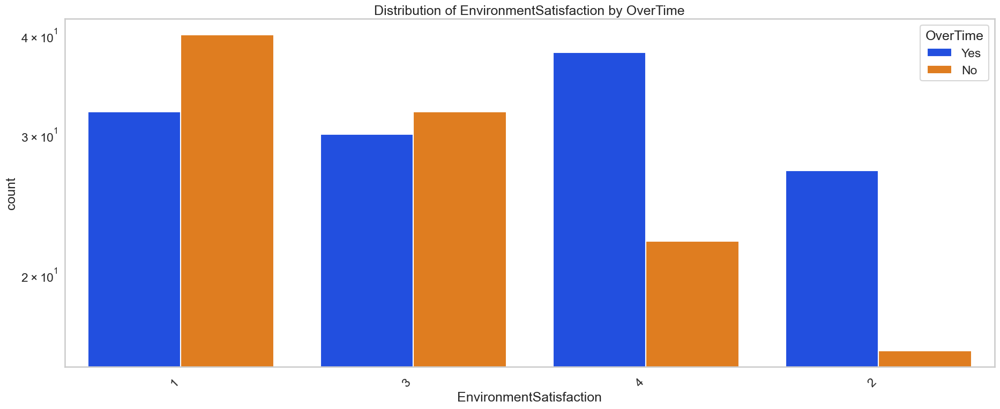

...

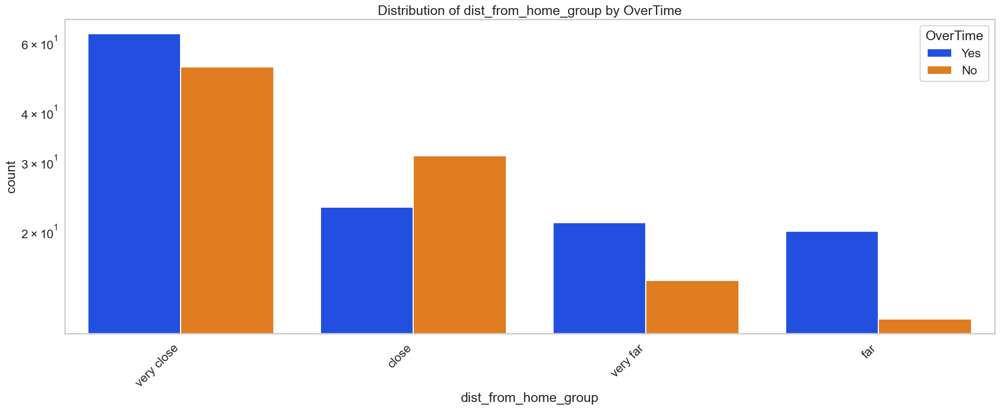

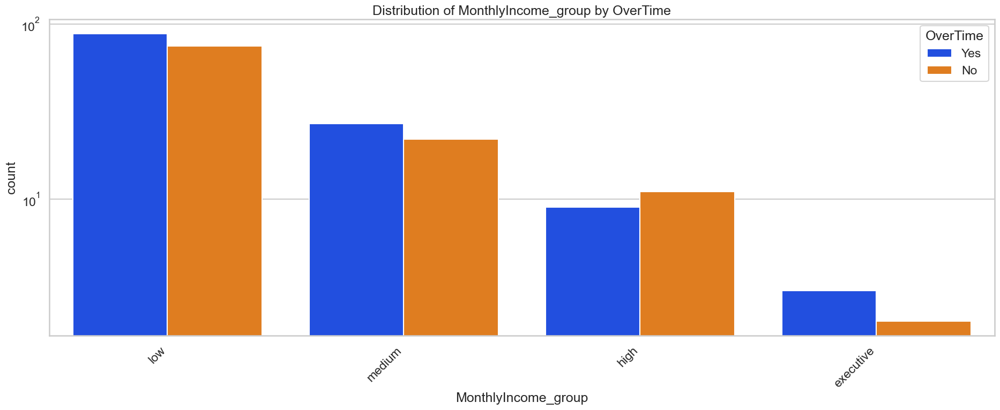

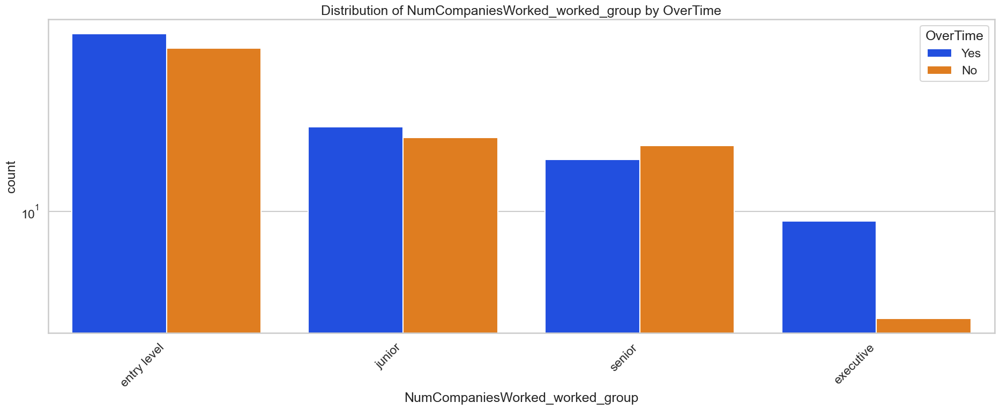

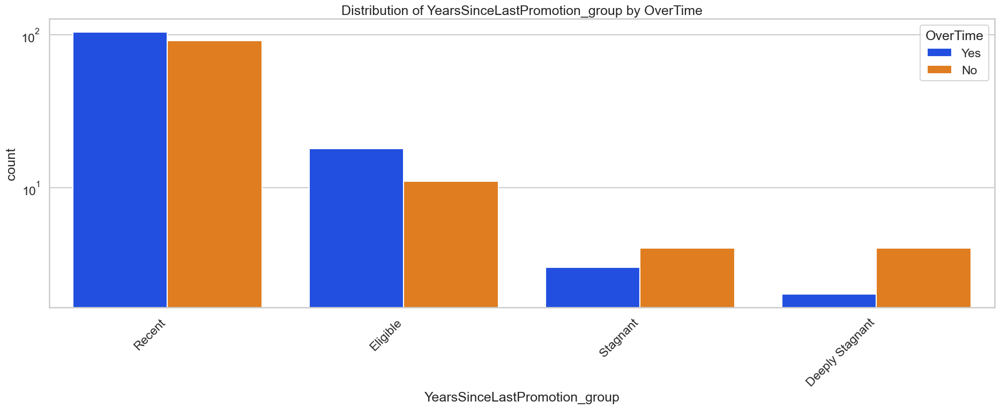

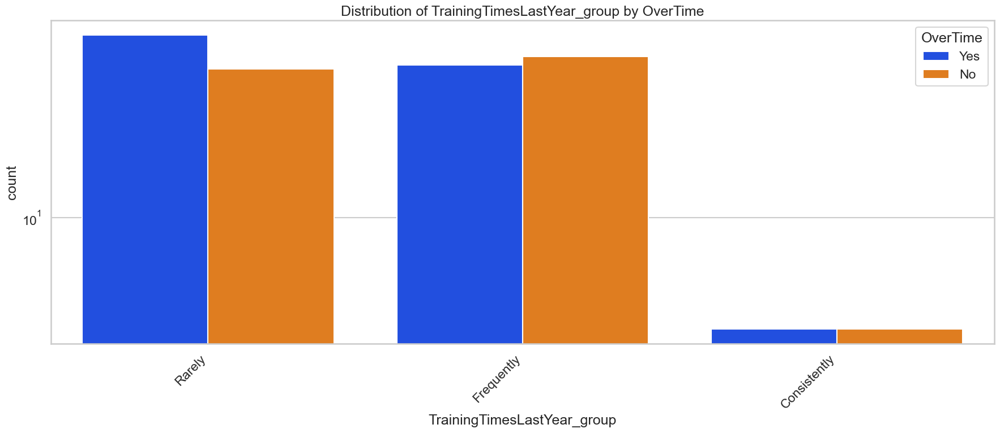

In [57]:
for col_name in categorical_columns:
    uniplot(
        dfs_1, 
        col=col_name, 
        hue='OverTime',
        title=f'Distribution of {col_name} by OverTime'
    )

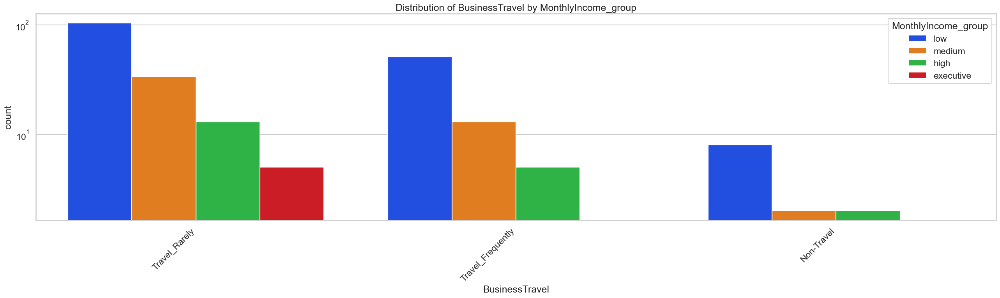

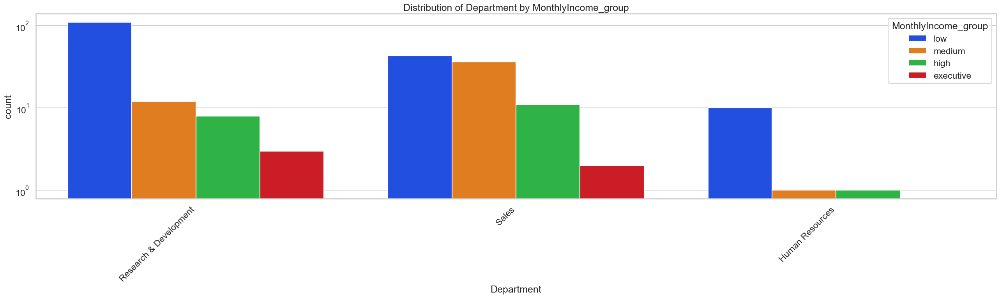

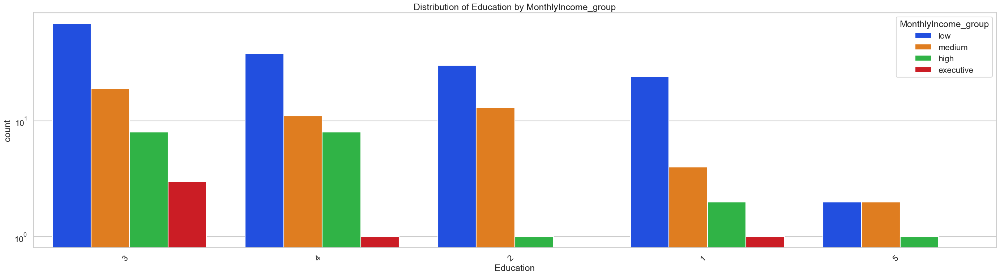

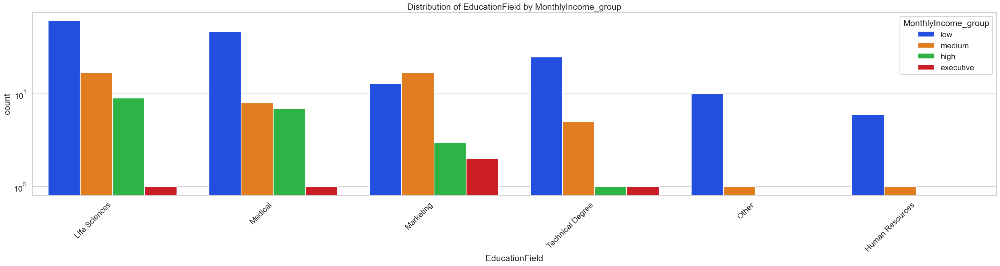

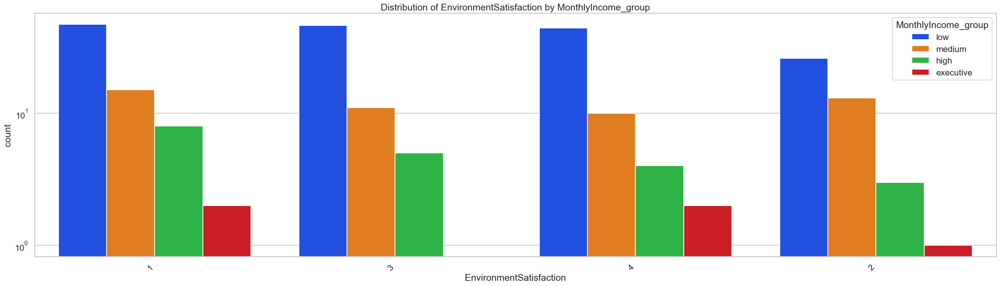

...

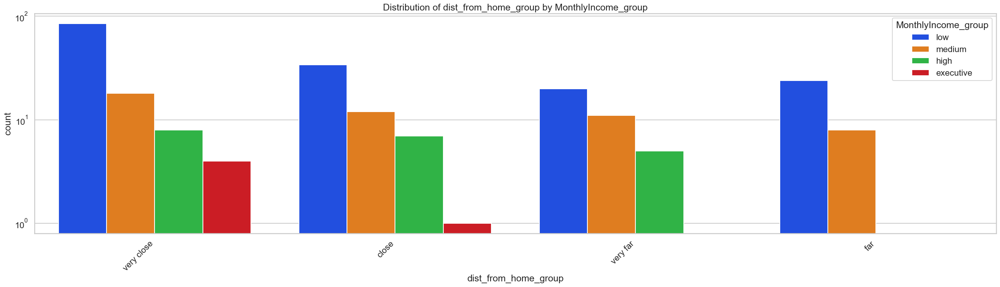

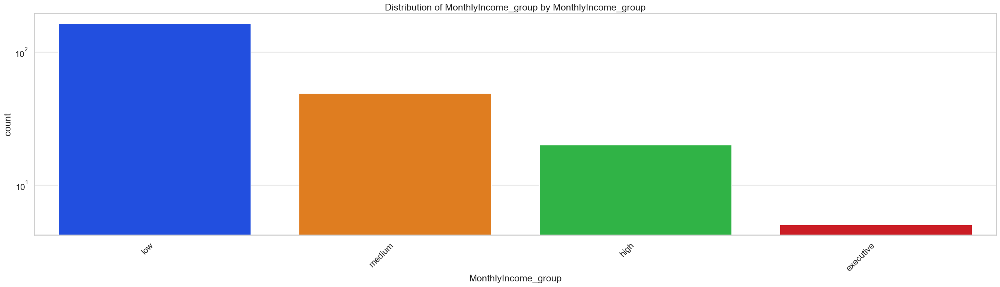

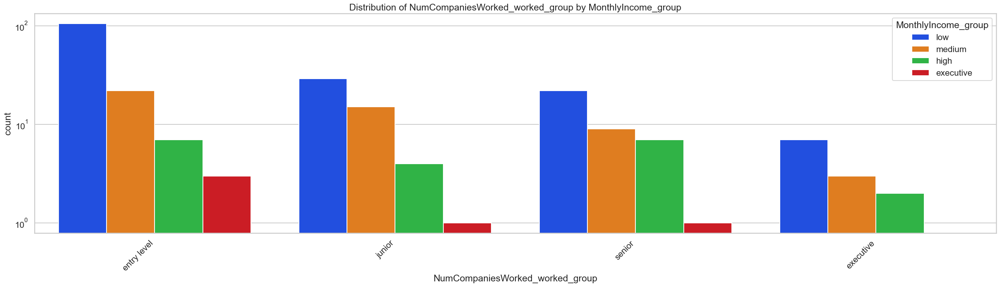

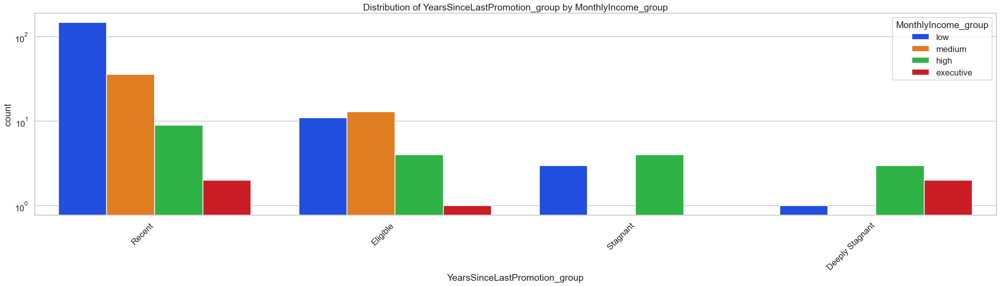

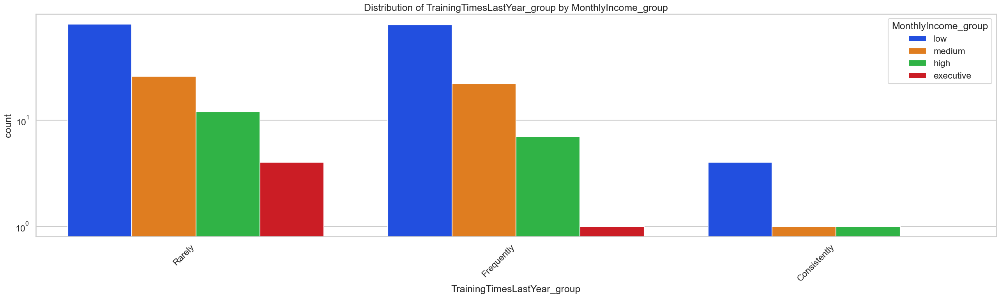

In [58]:
for col_name in categorical_columns:
    uniplot(
        dfs_1, 
        col=col_name, 
        hue='MonthlyIncome_group', 
        title=f'Distribution of {col_name} by MonthlyIncome_group')

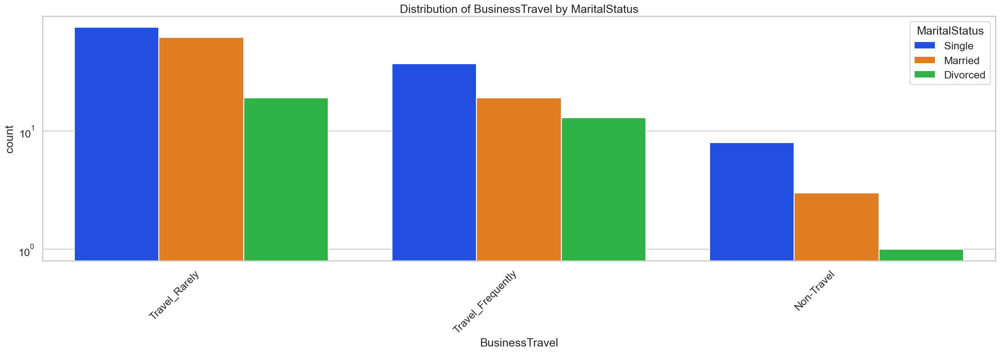

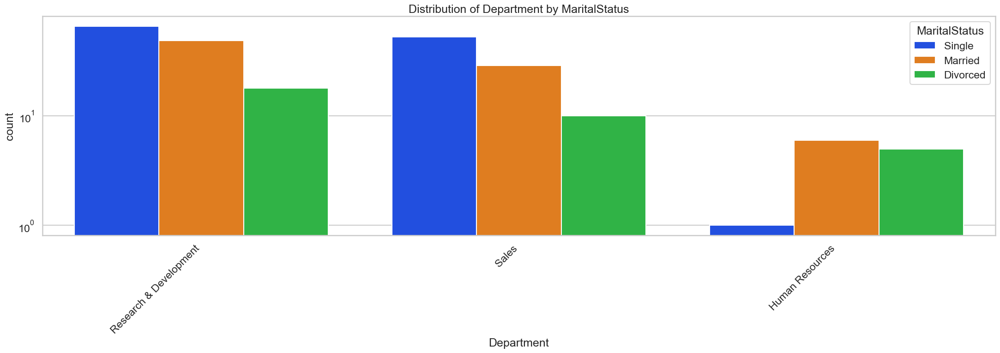

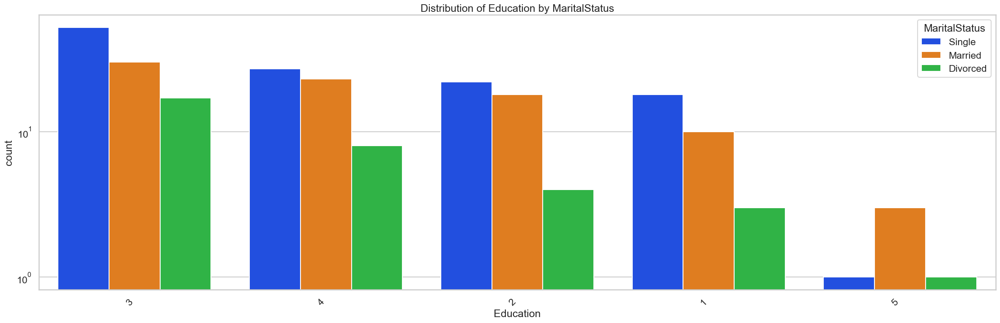

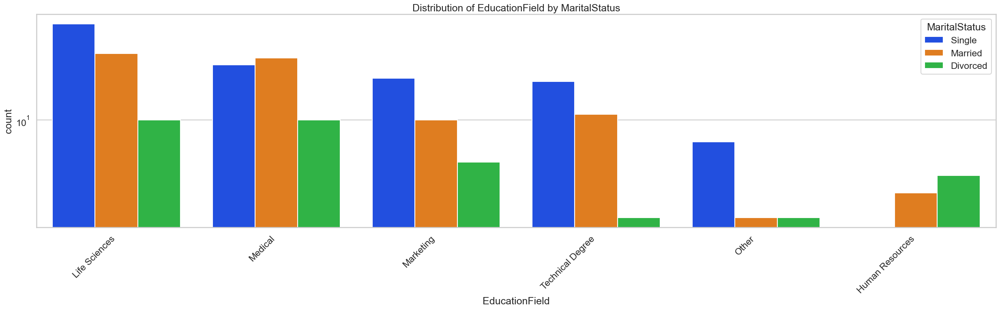

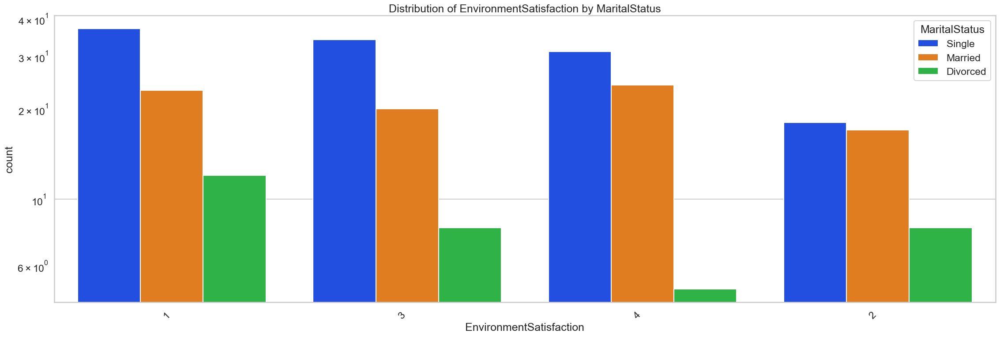

...

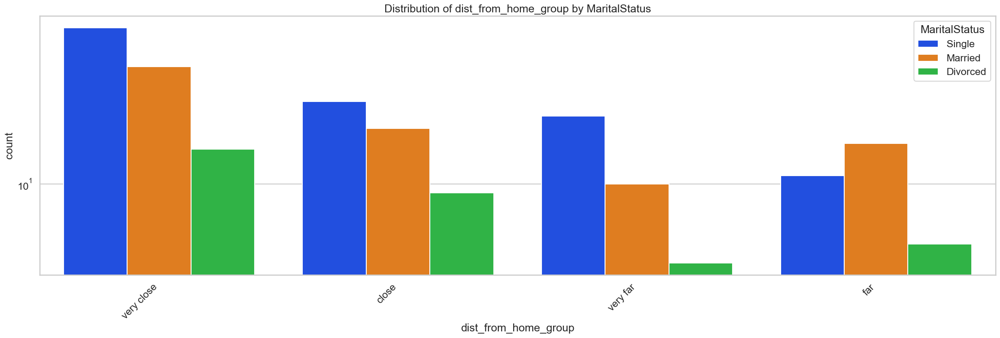

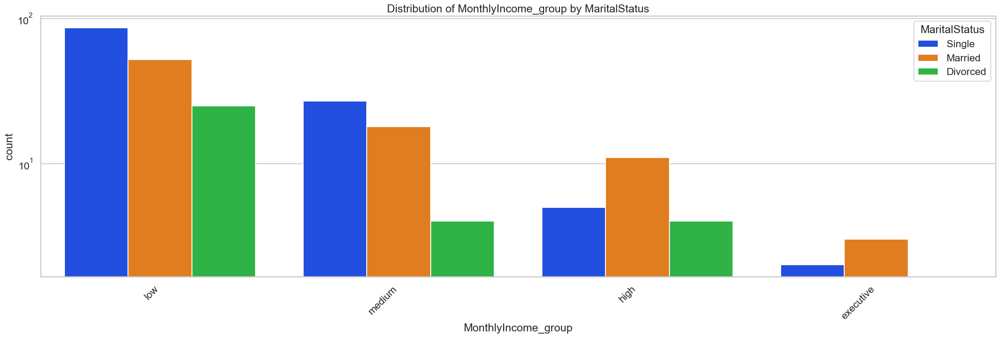

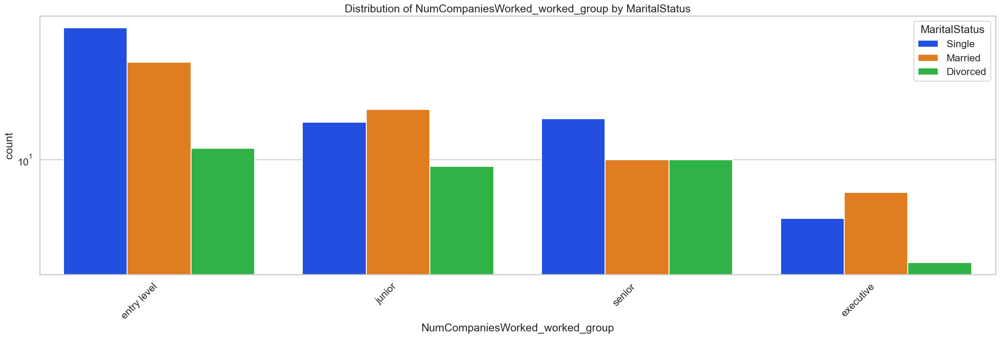

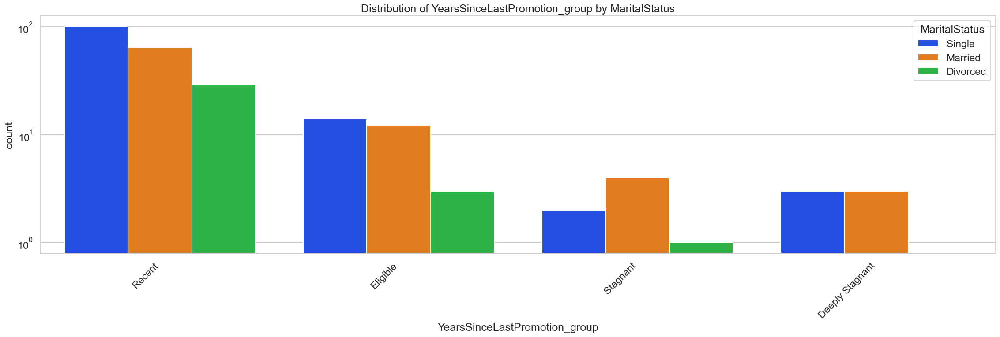

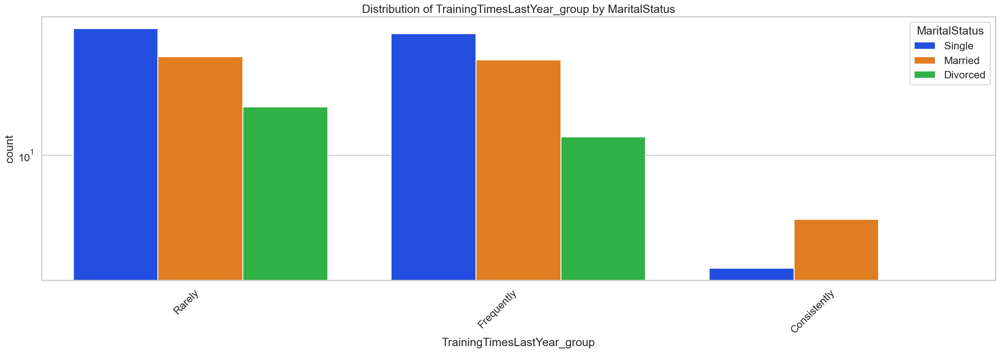

In [59]:
for col_name in categorical_columns:
    uniplot(
        dfs_1, 
        col=col_name, 
        hue='MaritalStatus', 
        title=f'Distribution of {col_name} by MaritalStatus')